<h1>Copernicus High-Resolution HR-WSI Water Products</h1>
From Visualization to Custom Water Monitoring: A showcase of the HRL WSI water product range and its applications

<h2>Introduction</h2>
This notebook completes the HR-WSI webinar series after the <b>snow</b> and <b>ice</b> notebooks and turns to the <b>water</b> products of the Copernicus Land Monitoring Service (CLMS): the High Resolution Water Layer package <b>HRWL</b> (WL, WPI, WCL) and the yearly Water Cover Duration <b>WCD</b>. Starting from an area of interest, it leads from data access and visual interpretation to custom water analyses:

- <b>Section 1</b>: Select an area of interest and download the water products through the CDSE OData API
- <b>Section 2</b>: Visualize and compare WL, WPI, WCL and WCD
- <b>Section 3</b>: Data analysis: (a) WCD statistics and a custom water mask, (b) hotspots of water area change, (c) trend in annual water duration

<b>Authors</b>: Christian Gruber, Rupert von der Kammer (GeoVille Information Systems and Data Processing GmbH, 2026)

<b>Prerequisites</b>
- An account on the <a href="https://dataspace.copernicus.eu/">Copernicus Data Space Ecosystem (CDSE)</a>
- A <a href="https://dataspace.copernicus.eu/analyse/jupyterlab">CDSE JupyterLab</a> session (Medium or Large server), or a local Python environment

The setup cells below prepare the folders, auxiliary files and Python packages.

<h3>Setup: Directories</h3>
This notebook is configured to run either on a machine in Copernicus' JupyterLab or locally on your own machine.</p>
<code>JupyterLab:</code> Files on the default working directory of CDSE's Jupyter Lab are deleted at the end of a session. This notebook therefore uses the 'mystorage' folder as default working directory when executed on the Jupyter Lab. Navigate to the <b>/mystorage/</b> folder and create a subfolder /mystorage/<b>2026-10-water_webinar</b>. This notebook should be placed inside this subfolder and run from here.

<code>Local:</code> If run locally, the working directory is set to the folder in which this notebook is stored.

<br>The notebook relies on three subdirectories: 
1) /products which serves as storage for downloaded WSI data, 
2) /results which stores all produced maps and tables, and 
3) /auxiliary which contains all auxiliary data necessary for running this exercise.

In [1]:
import getpass
import os
import importlib
import subprocess
import sys

# On CDSE JupyterLab, notebook + inputs live under mystorage (persistent storage).
# When running locally the current directory is used as the working directory.
CDSE_WORKING_DIR = os.path.expanduser("~/mystorage/2026-10-water_webinar")
WORKING_DIR = CDSE_WORKING_DIR if os.path.isdir(CDSE_WORKING_DIR) else "."
os.chdir(WORKING_DIR)
print("  Current working directory:", os.getcwd())

# All downloaded products are extracted here, kept separate from the notebook and input files
PRODUCTS_DIR = "products"
if not os.path.isdir(PRODUCTS_DIR):
    os.makedirs(PRODUCTS_DIR, exist_ok=True)
    print("    Products directory created:", os.path.abspath(PRODUCTS_DIR))
else:
    print("    Products directory found:", os.path.abspath(PRODUCTS_DIR))

# Reference/auxiliary inputs.
AUX_DIR = "auxiliary"
if not os.path.isdir(AUX_DIR):
    os.makedirs(AUX_DIR, exist_ok=True)
    print("    Auxiliary directory created:", os.path.abspath(AUX_DIR))
    print("    Ensure to place all necessary auxiliary input files in this directory.")
else:
    print("    Auxiliary directory found:", os.path.abspath(AUX_DIR))

# Exports of Section 3 (custom water mask, water bodies, trend rasters) are written here
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("    Results directory setup:", os.path.abspath(RESULTS_DIR))

print("\nDirectory setup complete. Folder structure is correct.")

  Current working directory: t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook
    Products directory found: t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook\products
    Auxiliary directory found: t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook\auxiliary
    Results directory setup: t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook\results

Directory setup complete. Folder structure is correct.


<h3>Setup: Auxiliary files</h3>
Load and check all necessary auxiliary data in the <code>auxiliary</code> folder:

| File | Required | Used for |
|---|---|---|
| `credentials.txt` | yes | CDSE login for the download in Section 1 (lines `username=...` and `password=...`); if missing, the cell below asks for username and password and creates it |
| `aoi.gpkg` | no | Area of interest in EPSG:3035 (Section 1); without it the AOI is drawn on a map or taken from a bounding box |
| `euhydro_danube_v013.gpkg` | no | Reference outlines of the water bodies for the hotspot detection in Section 3b |

<b>EU-Hydro</b> is the Copernicus pan-European river and lake network. It can be downloaded per river basin as GeoPackage from the <a href="https://land.copernicus.eu/en/products/eu-hydro/eu-hydro-river-network-database">Copernicus Land Monitoring Service</a>; For any AOI download that basin's file and set <code>EUHYDRO_PATH</code> in the cell below.

Without EU-Hydro, or if none of its water bodies lie in the AOI, Section 3b finds the water bodies in the WCD data itself.


In [2]:
CREDENTIALS_PATH = os.path.join(AUX_DIR, "credentials.txt") # CDSE login; created by this cell if it does not exist yet
AOI_PATH = os.path.join(AUX_DIR, "aoi.gpkg") # Area of Interest (AOI) file as a GeoPackage (.gpkg)
EUHYDRO_PATH = os.path.join(AUX_DIR, "euhydro_danube_v013.gpkg") # EU-Hydro (optional): reference outlines of the water bodies for Section 3b

# ------------------------------------------------------------------------------
import urllib.error
import urllib.parse
import urllib.request

print(f"Checking required input files in working directory: {os.getcwd()}\n")

CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

def check_cdse_login(username, password):
    """Ask CDSE for an access token: True if the login works, False if CDSE refuses it."""
    form = urllib.parse.urlencode({
        "client_id": "cdse-public",
        "grant_type": "password",
        "username": username,
        "password": password,
    }).encode()
    try:
        with urllib.request.urlopen(CDSE_TOKEN_URL, data=form, timeout=30):
            return True
    except urllib.error.HTTPError as err:
        if err.code in (400, 401):   # wrong username/password or account not activated
            print(f"  └[ERROR]  CDSE response: {err.read().decode(errors='replace')}")
            return False
        raise
    except urllib.error.URLError as err:
        raise RuntimeError(f"CDSE login server not reachable ({err.reason}). Check the internet connection.") from None


if os.path.isfile(CREDENTIALS_PATH):
    creds = {}
    with open(CREDENTIALS_PATH, encoding="utf-8") as f:
        for line in f:
            key, _, value = line.partition("=")
            creds[key.strip().lower()] = value.strip()
    username, password = creds.get("username"), creds.get("password")
    print(f"  [OK]      Found credentials.txt at {CREDENTIALS_PATH}")
    print(f"  └[INFO]   CDSE username used: {username or '(none found, check the file)'}")
    print(f"  └[INFO]   To use another CDSE username, delete '{CREDENTIALS_PATH}' and re-run this cell.")
    if not (username and password and check_cdse_login(username, password)):
        raise RuntimeError(f"CDSE login with '{CREDENTIALS_PATH}' failed. Delete the file and re-run this cell to enter your login again.")
else:
    print(f"  [MISSING] credentials.txt -> '{CREDENTIALS_PATH}' not found. Enter your CDSE login to create it.")
    username = input("CDSE username (email-address): ").strip()
    password = getpass.getpass("Password: ")
    if not username or not password:
        raise RuntimeError("Username or password not entered. Stopping.")
    if not check_cdse_login(username, password):
        raise RuntimeError("CDSE login failed, credentials.txt was not created. Re-run this cell and check username and password.")
    with open(CREDENTIALS_PATH, "w", encoding="utf-8") as f:
        f.write(f"username={username}\npassword={password}\n")
    print(f"  [OK]      Created credentials.txt at {CREDENTIALS_PATH} for CDSE username: {username}")
print("  └[OK]     CDSE login successful.")


if not os.path.isfile(AOI_PATH):
    print(f"\n  [MISSING] AOI -> '{AOI_PATH}' not found.")
    print("  └[INFO]   Please provide an AOI file to proceed.")
else:
    print(f"\n  [OK]      Found AOI at {AOI_PATH}")


EUHYDRO_LAYERS = ["InlandWater", "River_Net_p", "Canals_p", "Ditches_p", "Coastal_p"]

euhydro_layers = []   # the EU-Hydro layers Section 3b reads; empty -> water bodies are derived from the WCD
if os.path.isfile(EUHYDRO_PATH):
    euhydro_layers = list(EUHYDRO_LAYERS)   # layers missing from the file are skipped in Section 3b
    print(f"\n  [OK]      Found EU-Hydro at {EUHYDRO_PATH}")
else:
    print(f"\n  [MISSING] EU-Hydro -> '{EUHYDRO_PATH}' not found (optional, see the table above).")
    print("  └[INFO]   Section 3b will derive the water bodies from the WCD data instead.")

print("\nAuxiliary file setup complete. All required input files are present.")

Checking required input files in working directory: t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook

  [OK]      Found credentials.txt at auxiliary\credentials.txt
  └[INFO]   CDSE username used: vdkammer@geoville.com
  └[INFO]   To use another CDSE username, delete 'auxiliary\credentials.txt' and re-run this cell.
  └[OK]     CDSE login successful.

  [OK]      Found AOI at auxiliary\aoi.gpkg

  [OK]      Found EU-Hydro at auxiliary\euhydro_danube_v013.gpkg

Auxiliary file setup complete. All required input files are present.


<h3>Setup: Environment</h3>
CDSE Jupyter Lab contains most necessary packages. For standalone use of the notebook the following setup of the required python environment is required.
If packages are installed or an error occurs, restart kernel and run cell again.

In [3]:
required_packages = {
    "ipykernel": "ipykernel",
    "ipywidgets": "ipywidgets",
    "ipyleaflet": "ipyleaflet",
    "requests": "requests",
    "pandas": "pandas",
    "geopandas": "geopandas",
    "fiona": "fiona",
    "rasterio": "rasterio",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "shapely": "shapely",
    "contextily": "contextily",
    "affine": "affine<3",
}

# Upper version limits: package -> first major version that is NOT allowed.
version_caps = {
    "affine": 3,
}

missing = []
print("  Checking for required packages...")
for import_name, pip_name in required_packages.items():
    try:
        importlib.import_module(import_name)
    except ImportError:
        missing.append(pip_name)
        continue

    if import_name in version_caps:
        installed = importlib.metadata.version(import_name)
        major = int(installed.split(".")[0])
        if major >= version_caps[import_name]:
            print(f"  {import_name} {installed} is too new, need <{version_caps[import_name]}")
            missing.append(pip_name)

if missing:
    print(f"  Installing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--break-system-packages", *missing])
    print("  Done. Please restart the kernel to ensure all packages are properly loaded.")
    print("  \nExiting now to prepare for kernel restart...")
    sys.exit(0)  # Stop execution to allow the user to restart the kernel

print("\nEnvironment setup complete. All required packages are available.")

  Checking for required packages...

Environment setup complete. All required packages are available.


<h3>Setup: Libraries</h3>
All Python libraries used in this notebook are imported once. It is important that this cell runs through without any errors. If you encounter errors, check whether all necessary packages are installed in your environment.

In [4]:
# Standard library
import glob
import io
import os
import re
import time
import warnings
import zipfile
from urllib.parse import urljoin

# Data handling and web requests
import numpy as np
import pandas as pd
import requests

# Geospatial: vector (fiona, geopandas, shapely) and raster (rasterio)
import fiona
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask, rasterize, shapes
from rasterio.merge import merge
from rasterio.plot import plotting_extent
from shapely import force_2d
from shapely import wkt as shapely_wkt
from shapely.geometry import box, shape
from shapely.geometry.base import BaseGeometry

# Plotting
import contextily as cx
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch

# Notebook display and widgets (the interactive AOI map imports ipyleaflet in Section 1, as it is optional)
import ipywidgets as widgets
from IPython.display import display

print("Library setup complete. All libraries are imported.")


Library setup complete. All libraries are imported.


<h3>Setup: Constants and helper functions</h3>
Fixed product properties and the reusable building blocks of the notebook are defined in the next four cells. They cover data access, reading and colouring the layers, and drawing and exporting maps. The analysis steps themselves (custom water mask, hotspot detection, trend) are written out in their sections, so they can be followed there step by step.

Settings you may want to change (AOI, years, thresholds) are always at the top of the cell they affect, in <code>UPPER_CASE</code>.

<h4>Constants</h4>

| Constant | Content |
|---|---|
| `LAEA_CRS` | EPSG:3035 (ETRS89 / LAEA Europe), the grid of the LAEA products and of all processing |
| `CDSE_*_URL` | CDSE login, catalogue and download endpoints |
| `WATER_DATASETS` | OData `datasetIdentifier` of the HR-WSI water products: **HRWL** (multi-year High Resolution Water Layer) and **WCD** (yearly Water Cover Duration), each on UTM 10 m and LAEA 10 m / 100 m tiling |
| `LAYERS`, `NODATA` | Per layer (WL, WPI, WCL, WCD): product, name, largest regular value (larger = flag) and unit; 'no data' code per bit depth |
| `HRWL_DAYS` | Water day thresholds of the WL definition: temporary water from 91 days, permanent water from 274 days |
| `MASK_CLASSES`, `MASK_NODATA` | Class codes of the WL, reused for the custom water mask |
| `OUTSIDE_AOI_COLOUR`, `LOSS_GAIN_CMAP` | Map background outside the AOI; red-white-blue colour scale for water loss and gain |

In [5]:
# --- Grid ---------------------------------------------------------------------
LAEA_CRS = "EPSG:3035"                        # ETRS89 / LAEA Europe, grid of the LAEA products

# --- CDSE endpoints -----------------------------------------------------------
CDSE_TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
CDSE_CATALOGUE_URL = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
CDSE_DOWNLOAD_URL = "https://download.dataspace.copernicus.eu/odata/v1/Products({product_id})/$value"

# --- HR-WSI water datasets (OData attribute 'datasetIdentifier') --------------
# HRWL: multi-year High Resolution Water Layer package (LAEA: WL, WPI and WCL layers; UTM: WL only),
# WCD: yearly Water Cover Duration.
# Each is distributed on a UTM (Sentinel-2 tile) and a LAEA (EEA grid) tiling; UTM 10 m is used by default.
WATER_DATASETS = {
    "HRWL": {
        "full_name": "High Resolution Water Layer",
        "utm_10m": "clms_wsi_high-resolution-water-layer_europe_utm_10m_3yearly_v1",
        "laea_10m": "clms_wsi_high-resolution-water-layer_europe_laea_10m_3yearly_v1",
        "laea_100m": "clms_wsi_high-resolution-water-layer_europe_laea_100m_3yearly_v1",
    },
    "WCD": {
        "full_name": "Water Cover Duration",
        "utm_10m": "clms_wsi_water-cover-duration_europe_utm_10m_yearly_v1",
        "laea_10m": "clms_wsi_water-cover-duration_europe_laea_10m_yearly_v1",
        "laea_100m": "clms_wsi_water-cover-duration_europe_laea_100m_yearly_v1",
    },
}

# --- Layers -------------------------------------------------------------------
# Regular value range of each layer; larger values are flags (cloud or cloud shadow, sea water, no data)
LAYERS = {
    "WL":  {"product": "HRWL", "long_name": "Water Layer",            "max_valid": 2,   "unit": "class"},
    "WPI": {"product": "HRWL", "long_name": "Water Presence Index",   "max_valid": 100, "unit": "water presence (%)"},
    "WCL": {"product": "HRWL", "long_name": "Water Confidence Layer", "max_valid": 100, "unit": "confidence (%)"},
    "WCD": {"product": "WCD",  "long_name": "Water Cover Duration",   "max_valid": 366, "unit": "days with water"},
}
NODATA = {"uint8": 255, "uint16": 65535}   # 'no data' code of the 8-bit HRWL layers and the 16-bit WCD

# --- Water classes (codes of the HRWL WL) -------------------------------------
HRWL_DAYS = (91, 274)   # WL definition: temporary water from 3 months (25 %), permanent from 9 months (75 %)
MASK_NODATA = 255
MASK_CLASSES = {0: "dry", 1: "permanent water", 2: "temporary water"}   # codes of the HRWL WL

# --- Map style ----------------------------------------------------------------
OUTSIDE_AOI_COLOUR = "0.92"                   # grey background for pixels outside the AOI
LOSS_GAIN_CMAP = LinearSegmentedColormap.from_list("loss_gain", ["#a3302f", "#e34948", "#f0efec", "#3987e5", "#184f95"])

print("Constants defined.")


Constants defined.


<h4>Helper functions: CDSE data access</h4>

| Helper | Purpose |
|---|---|
| `read_credentials()` | Reads username and password from `credentials.txt` |
| `get_token()` | Logs in to CDSE and caches the access token; logs in again shortly before it expires |
| `aoi_to_wkt()` | Turns a bounding box, WKT, shapely geometry, GeoDataFrame or vector file into the WGS84 WKT used for the spatial filter |
| `build_odata_filter()` | Builds the OData filter for one dataset, AOI and time range |
| `search_products()` | Queries the CDSE OData catalogue and returns a table of matching products |
| `download_products()` | Downloads the products of a search result by their OData Id (with text progress bar, retries and automatic token renewal), skipping products that are already present |
| `extract_zip()` | Unzips a downloaded product into its own folder and removes the zip |

In [6]:
# --- Access token handling ---------------------------------------------------
def read_credentials(path):
    """Read 'key=value' lines (username, password) from a text file into a dict."""
    creds = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            key, value = line.split("=", 1)
            creds[key.strip().lower()] = value.strip()
    missing = {"username", "password"} - creds.keys()
    if missing:
        raise ValueError(f"credentials file '{path}' lacks: {', '.join(sorted(missing))}")
    return creds


# Last token and the time it stops being valid; get_token() logs in again shortly before that
_token_cache = {"token": None, "expires_at": 0.0}


def get_token(credentials, force_renew=False):
    """Return a CDSE access token, logging in again when the cached one is about to expire."""
    if force_renew or time.time() > _token_cache["expires_at"] - 60:
        response = requests.post(CDSE_TOKEN_URL, timeout=30, data={
            "client_id": "cdse-public",
            "grant_type": "password",
            "username": credentials["username"],
            "password": credentials["password"],
        })
        if response.status_code != 200:
            raise RuntimeError(f"CDSE login failed ({response.status_code}): {response.text[:200]}")
        payload = response.json()
        _token_cache["token"] = payload["access_token"]
        _token_cache["expires_at"] = time.time() + payload.get("expires_in", 600)
    return _token_cache["token"]


# --- Area of interest --------------------------------------------------------
def aoi_to_wkt(aoi, simplify_tolerance=None):
    """Convert an AOI to a WGS84 WKT string for the OData Intersects filter.

    Accepted inputs: bounding box (minx, miny, maxx, maxy) in lon/lat, a WKT string,
    a shapely geometry (assumed WGS84), a GeoDataFrame/GeoSeries, or a path to a
    vector file (shapefile, GeoPackage, GeoJSON). Multiple features are dissolved.
    """
    def dissolve(frame):
        frame = frame.to_crs(4326)
        # union_all() exists from geopandas 1.0 on, unary_union before
        return frame.union_all() if hasattr(frame, "union_all") else frame.unary_union

    if isinstance(aoi, (tuple, list)) and len(aoi) == 4:
        geom = box(*aoi)
    elif isinstance(aoi, BaseGeometry):
        geom = aoi
    elif isinstance(aoi, (gpd.GeoDataFrame, gpd.GeoSeries)):
        geom = dissolve(aoi)
    elif isinstance(aoi, str) and os.path.isfile(aoi):
        geom = dissolve(gpd.read_file(aoi))
    elif isinstance(aoi, str):
        geom = shapely_wkt.loads(aoi)
    else:
        raise TypeError(f"Unsupported AOI type: {type(aoi).__name__}")
    # Long geometries make the request URL too long -> optionally simplify (degrees)
    if simplify_tolerance:
        geom = geom.simplify(simplify_tolerance, preserve_topology=True)
    return geom.wkt


# --- OData search ------------------------------------------------------------
def build_odata_filter(dataset_id, aoi_wkt, start_date, end_date):
    """OData $filter: one dataset, intersecting the AOI, sensing start within [start_date, end_date]."""
    return " and ".join([
        "Attributes/OData.CSC.StringAttribute/any("
        f"a:a/Name eq 'datasetIdentifier' and a/OData.CSC.StringAttribute/Value eq '{dataset_id}')",
        f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi_wkt}')",
        f"ContentDate/Start ge {start_date}T00:00:00.000Z",
        f"ContentDate/Start le {end_date}T23:59:59.999Z",
    ])


def search_products(dataset_id, aoi_wkt, start_date, end_date, page_size=200):
    """Query the CDSE OData catalogue and return the matching products as a DataFrame.

    Follows '@odata.nextLink' so results larger than one page are returned completely.
    The catalogue is public, no token is needed for searching.
    """
    params = {
        "$filter": build_odata_filter(dataset_id, aoi_wkt, start_date, end_date),
        "$orderby": "ContentDate/Start asc",
        "$top": page_size,
    }
    records, url = [], CDSE_CATALOGUE_URL
    while url:
        response = requests.get(url, params=params, timeout=120)
        response.raise_for_status()
        page = response.json()
        records.extend(page.get("value", []))
        url, params = page.get("@odata.nextLink"), None  # nextLink already carries the query

    columns = ["Id", "Name", "start", "end", "size_mb", "online", "footprint"]
    if not records:
        return pd.DataFrame(columns=columns)
    df = pd.DataFrame({
        "Id": [r["Id"] for r in records],
        "Name": [r["Name"] for r in records],
        "start": pd.to_datetime([r["ContentDate"]["Start"] for r in records]),
        "end": pd.to_datetime([r["ContentDate"]["End"] for r in records]),
        "size_mb": [round(r.get("ContentLength", 0) / 1e6, 1) for r in records],
        "online": [r.get("Online", True) for r in records],
        "footprint": [r.get("Footprint") for r in records],
    })
    return df.drop_duplicates("Name").reset_index(drop=True)


# --- Download & unzip --------------------------------------------------------
def _get_following_redirects(url, credentials, max_redirects=5, **kwargs):
    """GET that keeps the Authorization header across redirects to other hosts.

    requests drops the header when the host changes, but CDSE redirects downloads
    between its own hosts, so redirects are followed manually here.
    """
    for _ in range(max_redirects + 1):
        headers = {"Authorization": f"Bearer {get_token(credentials)}"}
        response = requests.get(url, headers=headers, allow_redirects=False, **kwargs)
        if response.status_code in (301, 302, 303, 307, 308):
            url = urljoin(url, response.headers["Location"])
            response.close()
            continue
        return response
    raise RuntimeError(f"Too many redirects for {url}")


def extract_zip(zip_path, target_dir, remove_zip=True):
    """Extract a product zip into target_dir and return the product folder path.

    Members resolving outside target_dir are rejected (zip-slip protection).
    """
    target_root = os.path.realpath(target_dir)
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.namelist():
            dest = os.path.realpath(os.path.join(target_root, member))
            if os.path.commonpath([target_root, dest]) != target_root:
                raise RuntimeError(f"Unsafe path in archive {zip_path}: {member}")
        top_level = {m.split("/")[0] for m in zf.namelist() if m.strip("/")}
        zf.extractall(target_root)
    if remove_zip:
        os.remove(zip_path)
    # Products zip into a single top-level folder; fall back to the target dir otherwise
    return os.path.join(target_dir, top_level.pop()) if len(top_level) == 1 else target_dir


def download_products(products, credentials, out_dir, extract=True, chunk_size=1 << 20, retries=3, overwrite=False):
    """Download the products of a search_products() DataFrame into out_dir and (optionally) unzip them.

    Products whose folder (or zip, with extract=False) already exists are skipped.
    A partial download is written to '<name>.zip.part' and only renamed when complete.
    Returns the paths of the extracted folders (or zip files), in the order of the table.
    """
    os.makedirs(out_dir, exist_ok=True)
    paths = []
    total_count = len(products)

    bar_width = min(20, total_count)   # one character per product for fewer than 20 products

    def show_progress(done):
        # Text bar, e.g. '▮▮▮▮▮▯▯▯▯▯▯▯▯▯▯▯▯▯▯▯ 5/20 (25%)', updated in place on one line
        filled = round(bar_width * done / total_count)
        print(f"\r{' ' * 12}{'▮' * filled}{'▯' * (bar_width - filled)} {done}/{total_count} ({done / total_count:.0%})",
              end="\n" if done == total_count else "", flush=True)

    if total_count:
        show_progress(0)
    for done, row in enumerate(products.itertuples(index=False), start=1):
        product_dir = os.path.join(out_dir, row.Name)
        zip_path = os.path.join(out_dir, f"{row.Name}.zip")
        if extract and os.path.isdir(product_dir) and not overwrite:
            paths.append(product_dir)
            show_progress(done)
            continue
        if not os.path.isfile(zip_path) or overwrite:
            url = CDSE_DOWNLOAD_URL.format(product_id=row.Id)
            part_path = zip_path + ".part"
            for attempt in range(1, retries + 1):
                try:
                    with _get_following_redirects(url, credentials, stream=True, timeout=(30, 300)) as response:
                        if response.status_code == 401 and attempt < retries:
                            get_token(credentials, force_renew=True)
                            continue
                        response.raise_for_status()
                        with open(part_path, "wb") as f:
                            for chunk in response.iter_content(chunk_size):
                                f.write(chunk)
                    os.replace(part_path, zip_path)
                    break
                except (requests.ConnectionError, requests.Timeout, requests.HTTPError) as err:
                    if attempt == retries:
                        print()   # keep the error message off the progress bar line
                        raise RuntimeError(f"Download of {row.Name} failed after {retries} attempts: {err}") from err
                    time.sleep(5 * attempt)
        paths.append(extract_zip(zip_path, out_dir) if extract else zip_path)
        show_progress(done)
    return paths


print("CDSE access functions defined.")


CDSE access functions defined.


<h4>Helper functions: Layers, legends and statistics</h4>

| Helper | Purpose |
|---|---|
| `layer_files()` | Finds all tiles of a layer in `products`, grouped by period (e.g. `20160901P64M`, `20200901P1Y`) |
| `period_label()` | Turns a period code into a readable label (`2016-09 to 2021-12`, `2020/21`) |
| `read_layer()` | Mosaics the tiles over the AOI; pixels outside the AOI polygon are masked |
| `as_values()` | Float copy of a layer with NaN for flagged pixels, used for all statistics |
| `read_legend()` | Reads the official colour table (`.clr`) from the product's `legend` folder |
| `legend_rgba()` | Colours a layer with its legend for display |
| `legend_patches()`, `add_layer_legend()` | Class legend or colour bar of a layer, plus the flags present in the AOI |
| `describe()`, `wcd_statistics()` | Mean, min, max and standard deviation of WCD days, for all AOI pixels and for water pixels only |

In [7]:
# --- Layer handling functions ------------------------------------------------
def layer_files(layer):
    """Find all tiles of one layer in PRODUCTS_DIR, grouped by period: {'20160901P64M': [path, ...], ...}."""
    pattern = os.path.join(PRODUCTS_DIR, f"CLMS_WSI_{LAYERS[layer]['product']}_010m_*", f"*_{layer}.tif")
    by_period = {}
    for path in sorted(glob.glob(pattern)):
        period = re.search(r"_(\d{8}P\d+[MY])_", os.path.basename(path)).group(1)
        by_period.setdefault(period, []).append(path)
    if not by_period:
        raise FileNotFoundError(f"No {layer} files in {PRODUCTS_DIR}. Run the download in Section 1 first.")
    return by_period


def period_label(period):
    """'20160901P64M' -> '2016-09 to 2021-12'; a one-year period '20200901P1Y' -> '2020/21'."""
    start = pd.Timestamp(period[:8])
    count, unit = int(period[9:-1]), period[-1]
    if unit == "Y" and count == 1:
        return f"{start.year}/{(start.year + 1) % 100:02d}"
    end = start + pd.DateOffset(months=count * (12 if unit == "Y" else 1)) - pd.Timedelta(days=1)
    return f"{start:%Y-%m} to {end:%Y-%m}"


def read_layer(paths, aoi):
    """Mosaic the tiles of one layer over the AOI and return (masked array, transform).

    Pixels outside the AOI polygon are masked. AOI pixels that no tile covers
    get the layer's 'no data' code.
    """
    with rasterio.open(paths[0]) as src:
        nodata = NODATA[src.dtypes[0]]
        xres, yres = src.res
    # Snap the window outwards to the 10 m grid, so the pixels stay exactly those of the files
    minx, miny, maxx, maxy = aoi.total_bounds
    bounds = (np.floor(minx / xres) * xres, np.floor(miny / yres) * yres,
              np.ceil(maxx / xres) * xres, np.ceil(maxy / yres) * yres)
    mosaic, transform = merge(paths, bounds=bounds, nodata=nodata)
    outside = geometry_mask(aoi.geometry, out_shape=mosaic.shape[1:], transform=transform)
    return np.ma.MaskedArray(mosaic[0], mask=outside), transform


def as_values(data, layer):
    """Float copy of a layer with NaN for flagged pixels and pixels outside the AOI."""
    values = data.data.astype(np.float32)
    values[np.ma.getmaskarray(data) | (data.data > LAYERS[layer]["max_valid"])] = np.nan
    return values


def read_legend(layer_path):
    """Read the colour table (.clr) in the product's 'legend' folder as {value: (RGBA 0-1, label)}."""
    layer = os.path.basename(layer_path)[:-len(".tif")].rsplit("_", 1)[1].lower()   # e.g. 'wcd'
    matches = glob.glob(os.path.join(os.path.dirname(layer_path), "legend", f"*_{layer}.clr"))
    if not matches:
        raise FileNotFoundError(f"No colour table for {layer.upper()} in the legend folder of {layer_path}")
    legend = {}
    with open(matches[0], encoding="utf-8") as f:
        for line in f:
            fields = line.split(maxsplit=5)            # value R G B A label
            if len(fields) == 6:
                value, *rgba = (int(v) for v in fields[:5])
                legend[value] = (tuple(c / 255 for c in rgba), fields[5].strip())
    return legend


def legend_rgba(data, legend):
    """Colour a (masked) layer with its legend as an RGBA image; masked or unknown values stay transparent."""
    codes = np.array(sorted(legend))
    colours = np.array([legend[c][0] for c in codes] + [(0, 0, 0, 0)])
    colours = np.round(colours * 255).astype(np.uint8)
    raw = np.ma.getdata(data)
    index = np.minimum(np.searchsorted(codes, raw), len(codes) - 1)
    index[(codes[index] != raw) | np.ma.getmaskarray(data)] = len(codes)   # -> transparent
    return colours[index]


def legend_patches(legend, codes, with_code=True):
    """Legend patches for the given codes, labelled with the legend text (and the code)."""
    return [Patch(facecolor=legend[c][0], edgecolor="0.5", label=f"{c}: {legend[c][1]}" if with_code else legend[c][1])
            for c in codes]


def add_layer_legend(ax, layer, data, legend):
    """Class legend for categorical layers, colour bar for continuous ones; plus the flags found in the AOI."""
    max_valid = LAYERS[layer]["max_valid"]
    present = set(np.unique(data.compressed()).tolist())
    flags = legend_patches(legend, [c for c in sorted(legend) if c > max_valid and c in present])
    if max_valid <= 10:
        classes = legend_patches(legend, [c for c in sorted(legend) if c <= max_valid])
        ax.legend(handles=classes + flags, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3,
                  frameon=False, fontsize=9)
    else:
        ramp = ListedColormap([legend[c][0] for c in range(max_valid + 1) if c in legend])
        bar = ax.figure.colorbar(ScalarMappable(Normalize(-0.5, max_valid + 0.5), ramp), ax=ax,
                                 location="bottom", shrink=0.8, pad=0.02, aspect=40)
        bar.set_label(LAYERS[layer]["unit"], fontsize=9)
        bar.outline.set_edgecolor("0.6")
        if flags:
            ax.legend(handles=flags, loc="upper right", fontsize=8, framealpha=0.9)


# --- WCD statistics ----------------------------------------------------------
def describe(values):
    """Mean, min, max and standard deviation of an array without NaN (NaN for an empty array)."""
    if values.size == 0:
        return dict.fromkeys(["mean", "min", "max", "std"], np.nan)
    return {"mean": values.mean(), "min": values.min(), "max": values.max(), "std": values.std()}


def wcd_statistics(layers, pixel_area_km2):
    """One row of statistics for a (years x pixels) or (pixels) array of WCD days."""
    observed = layers[~np.isnan(layers)]
    wet = observed[observed > 0]
    n_years = layers.shape[0] if layers.ndim == 2 else 1
    return {
        ("", "flagged (%)"): 100 * (1 - observed.size / layers.size),
        **{("all AOI pixels", key): value for key, value in describe(observed).items()},
        ("water pixels (WCD > 0)", "area (km²)"): wet.size * pixel_area_km2 / n_years,
        **{("water pixels (WCD > 0)", key): value for key, value in describe(wet).items()},
    }


print("Layer, legend and statistics functions defined.")


Layer, legend and statistics functions defined.


<h4>Helper functions: Maps and export</h4>

| Helper | Purpose |
|---|---|
| `map_axes()` | New map figure shaped like the AOI, with the AOI outline on a grey background |
| `add_basemap()` | Adds web map tiles below a map; skipped with a note when offline |
| `signed_percent()` | Axis label format for changes: `+12 %`, `-5 %`, `0 %` |
| `write_geotiff()` | Writes a single-band, compressed GeoTIFF on the LAEA grid, with optional colour table and metadata |
| `palette()` | Converts a legend into the colour table a GeoTIFF expects |

In [8]:
# --- Maps ---------------------------------------------------------------------
def map_axes(extent, aoi, width, extra_height):
    """New map figure for a raster of the AOI: grey outside the AOI, AOI outline, no axis ticks.

    The height follows the shape of the extent, plus extra_height inches for title and legend.
    """
    height = width * (extent[3] - extent[2]) / (extent[1] - extent[0]) + extra_height
    fig, ax = plt.subplots(figsize=(width, height), layout="constrained")
    ax.set_facecolor(OUTSIDE_AOI_COLOUR)
    aoi.boundary.plot(ax=ax, color="0.35", linewidth=0.8)
    ax.set_xticks([])
    ax.set_yticks([])
    return fig, ax


def add_basemap(ax, source=cx.providers.Esri.WorldTopoMap, **kwargs):
    """Add web map tiles below the plot (LAEA). The tiles need internet access; without it the map is kept as is."""
    try:
        cx.add_basemap(ax, crs=LAEA_CRS, source=source, **kwargs)
    except Exception as err:
        print(f"  [INFO]    Basemap not available: {err}")


def signed_percent(value, _position=None):
    """Tick label for a signed percentage: '+12 %', '-5 %', '0 %'. Usable as matplotlib formatter."""
    return f"{value:+.0f} %" if value else "0 %"


# --- GeoTIFF export -------------------------------------------------------------
def write_geotiff(path, array, transform, nodata, colormap=None, tags=None, crs=LAEA_CRS):
    """Write a single-band, LZW-compressed GeoTIFF on the LAEA grid, with an optional palette and metadata tags."""
    profile = {"driver": "GTiff", "height": array.shape[0], "width": array.shape[1], "count": 1,
               "dtype": array.dtype.name, "crs": crs, "transform": transform, "nodata": nodata,
               "compress": "lzw"}
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(array, 1)
        if colormap:
            dst.write_colormap(1, colormap)
        if tags:
            dst.update_tags(**tags)
    return path


def palette(legend, codes):
    """Legend colours as the 0-255 RGBA colour table GeoTIFF expects."""
    return {code: tuple(round(c * 255) for c in legend[code][0]) for code in codes}


print("Map and export functions defined.")


Map and export functions defined.


<h2>Section 1: Spatial selection and download water product</h2>
All HR-WSI water products available on the <b>LAEA 10 m</b> grid (EPSG:3035) are searched through the CDSE OData API for an area of interest (AOI) and downloaded to the <code>products</code> folder:

- <b>HRWL</b> (High Resolution Water Layer): multi-year package
- <b>WCD</b> (Water Cover Duration): one product per hydrological year (1 September – 31 August), from 2016 onwards

<h3>Step 1.1: Define the area of interest</h3>
The AOI is defined in one of three ways, in this order:
1. <b>AOI file</b>: if <code>aux/aoi.gpkg</code> exists, its first polygon in the first layer is used (change <code>AOI_LAYER</code> / <code>AOI_FEATURE</code> to pick another one). The coordinate system must be <b>EPSG:3035</b>.
2. <b>Interactive map</b>: without a valid AOI file, a map is shown on which a rectangle or polygon can be drawn (requires the <code>ipyleaflet</code> package).
3. <b>Bounding box</b>: if nothing is drawn, or no interactive map is available, a bounding box is used. The coordinates are entered in EPSG:4326 (WGS84) in the variable <code>AOI_BBOX</code>.

  [OK]      AOI file found: auxiliary\aoi.gpkg
  └[INFO]   Using polygon 1 of 1 in layer 'AOI_WSI-JN' (EPSG:3035)


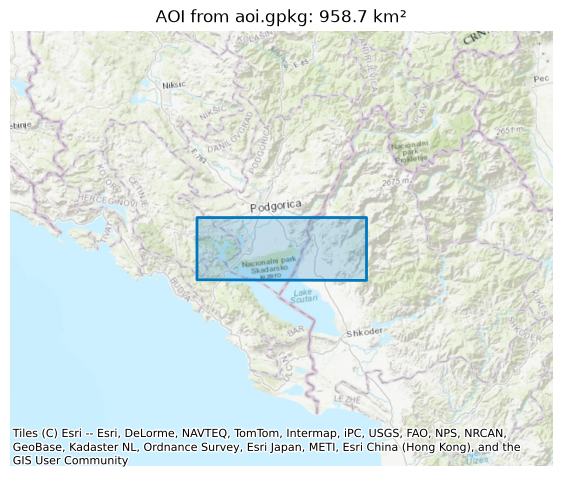

To use this AOI execute the next cell. 
For changing it edit the AOI file or remove it to use the interactive map for drawing an AOI instead.


In [9]:
AOI_FILE = os.path.join(AUX_DIR, "aoi.gpkg")
AOI_LAYER = None                              # layer name in AOI_FILE, None = first layer
AOI_FEATURE = 0                               # index of the polygon within that layer (0 = first)
AOI_BBOX = (16.65, 47.70, 16.90, 47.95)       # fallback: (min lon, min lat, max lon, max lat), WGS84

# --- Processing ---------------------------------------------------------------
aoi_from_file = None
drawn_aoi = []                                # filled by the map's draw control

if os.path.isfile(AOI_FILE):
    aoi_layer = AOI_LAYER if AOI_LAYER is not None else fiona.listlayers(AOI_FILE)[0]
    layer_gdf = gpd.read_file(AOI_FILE, layer=aoi_layer)
    polygons = layer_gdf[layer_gdf.geom_type.isin(["Polygon", "MultiPolygon"])]
    if polygons.empty:
        raise ValueError(f"Layer '{aoi_layer}' in {AOI_FILE} contains no polygons.")
    # The AOI file must be on the LAEA grid of the products; any other CRS -> draw the AOI on the map instead
    if layer_gdf.crs is not None and layer_gdf.crs.equals(LAEA_CRS):
        aoi_from_file = polygons.iloc[[AOI_FEATURE]]
        print(f"  [OK]      AOI file found: {AOI_FILE}")
        print(f"  └[INFO]   Using polygon {AOI_FEATURE + 1} of {len(polygons)} in layer '{aoi_layer}' ({LAEA_CRS})")
    else:
        found_crs = layer_gdf.crs.to_string() if layer_gdf.crs is not None else "no CRS"
        print(f"  [ERROR]   AOI file {AOI_FILE} is not in {LAEA_CRS} (found: {found_crs}). The file is ignored.")
        print(f"  └[INFO]   Reproject the file to {LAEA_CRS}, or draw the AOI on the map below.")

if aoi_from_file is not None:

    # Static overview map of the AOI in LAEA, with a margin of the AOI size around it
    aoi_preview = aoi_from_file.to_crs(LAEA_CRS)
    minx, miny, maxx, maxy = aoi_preview.total_bounds
    margin = 1.1 * max(maxx - minx, maxy - miny)
    fig, ax = plt.subplots(figsize=(7, 7))
    aoi_preview.plot(ax=ax, facecolor="#0077be33", edgecolor="#0077be", linewidth=2)
    ax.set_xlim(minx - margin, maxx + margin)
    ax.set_ylim(miny - margin, maxy + margin)
    add_basemap(ax)
    ax.set_title(f"AOI from {os.path.basename(AOI_FILE)}: {aoi_preview.area.iloc[0] / 1e6:,.1f} km²")
    ax.set_axis_off()
    plt.show()
    print(f"To use this AOI execute the next cell. \n"
          f"For changing it edit the AOI file or remove it to use the interactive map for drawing an AOI instead.")
else:
    if not os.path.isfile(AOI_FILE):
        print(f"  [INFO]    No AOI file at {AOI_FILE}")
    try:
        from ipyleaflet import Map, DrawControl, basemaps

        def on_draw(target, action, geo_json):
            if action in ("created", "edited"):
                drawn_aoi[:] = [geo_json["geometry"]]
            elif action == "deleted":
                drawn_aoi.clear()

        aoi_map = Map(center=((AOI_BBOX[1] + AOI_BBOX[3]) / 2, (AOI_BBOX[0] + AOI_BBOX[2]) / 2), zoom=9,
                      basemap=basemaps.OpenStreetMap.Mapnik, scroll_wheel_zoom=True)
        shape_style = {"shapeOptions": {"color": "#0077be", "fillOpacity": 0.15}}
        draw_control = DrawControl(rectangle=shape_style, polygon=shape_style,
                                   polyline={}, circle={}, circlemarker={}, marker={})
        draw_control.on_draw(on_draw)
        aoi_map.add(draw_control)
        print(f"  └[INFO]   Draw a rectangle or polygon on the map below, then run the next cell (converted to {LAEA_CRS}).")
        print(f"            Without a drawing, the bounding box AOI_BBOX = {AOI_BBOX} is used.")
        display(aoi_map)
    except ImportError:
        print("  └[INFO]   Interactive map not available (package 'ipyleaflet' missing).")
        print(f"            Using the bounding box AOI_BBOX = {AOI_BBOX}; edit it in this cell to change the AOI.")

In [10]:
if aoi_from_file is not None:
    aoi_input, aoi_source = aoi_from_file, f"AOI file {AOI_FILE}"
elif drawn_aoi:
    aoi_input = gpd.GeoDataFrame(geometry=[shape(drawn_aoi[-1])], crs="EPSG:4326")
    aoi_source = "shape drawn on the map"
else:
    aoi_input = gpd.GeoDataFrame(geometry=[box(*AOI_BBOX)], crs="EPSG:4326")
    aoi_source = f"bounding box {AOI_BBOX}"

# All further processing happens on the LAEA grid of the downloaded products
aoi_laea = aoi_input[["geometry"]].to_crs(LAEA_CRS).reset_index(drop=True)

print(f"  [OK]      AOI defined from {aoi_source}")
print(f"  └[INFO]   Area: {aoi_laea.area.iloc[0] / 1e6:,.1f} km² | bounds ({LAEA_CRS}): "
      + ", ".join(f"{v:,.0f}" for v in aoi_laea.total_bounds))
print("\nAOI setup complete.")

  [OK]      AOI defined from AOI file auxiliary\aoi.gpkg
  └[INFO]   Area: 958.7 km² | bounds (EPSG:3035): 5,063,600, 2,172,002, 5,114,579, 2,190,909

AOI setup complete.


<h3>Step 1.2: Search available products</h3>
Queries the CDSE catalogue for all HRWL and WCD products on the LAEA 10 m grid that intersect the AOI, from 2016 until today. A map shows the AOI and the product tiles that cover it.

,products,tiles,first_start,last_end,size_mb
product,,,,,
HRWL,2,2,2016-09-01 00:00:00+00:00,2021-12-31 23:59:59+00:00,30.9
WCD,20,2,2016-09-01 00:00:00+00:00,2026-08-31 23:59:59+00:00,45.7


  [INFO]   More than 10 products found (22). Displaying first 10 products:


,product,tile,Name,start,end,size_mb,online
0,HRWL,E50N21,CLMS_WSI_HRWL_010m_E50N21_20160901P64M_COMB_V100,2016-09-01,2021-12-31,7.7,True
1,HRWL,E51N21,CLMS_WSI_HRWL_010m_E51N21_20160901P64M_COMB_V100,2016-09-01,2021-12-31,23.2,True
2,WCD,E51N21,CLMS_WSI_WCD_010m_E51N21_20160901P1Y_COMB_V100,2016-09-01,2017-08-31,2.4,True
3,WCD,E50N21,CLMS_WSI_WCD_010m_E50N21_20160901P1Y_COMB_V100,2016-09-01,2017-08-31,2.1,True
4,WCD,E51N21,CLMS_WSI_WCD_010m_E51N21_20170901P1Y_COMB_V100,2017-09-01,2018-08-31,2.8,True
5,WCD,E50N21,CLMS_WSI_WCD_010m_E50N21_20170901P1Y_COMB_V100,2017-09-01,2018-08-31,2.3,True
6,WCD,E51N21,CLMS_WSI_WCD_010m_E51N21_20180901P1Y_COMB_V100,2018-09-01,2019-08-31,2.3,True
7,WCD,E50N21,CLMS_WSI_WCD_010m_E50N21_20180901P1Y_COMB_V100,2018-09-01,2019-08-31,2.0,True
8,WCD,E51N21,CLMS_WSI_WCD_010m_E51N21_20190901P1Y_COMB_V100,2019-09-01,2020-08-31,2.3,True
9,WCD,E50N21,CLMS_WSI_WCD_010m_E50N21_20190901P1Y_COMB_V100,2019-09-01,2020-08-31,2.0,True


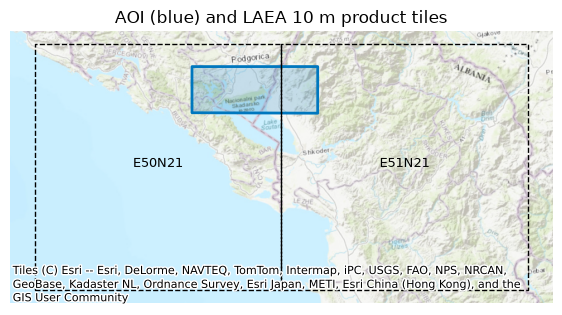

In [11]:
START_DATE = "2016-01-01"
END_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")

# The convex hull keeps the query short for detailed AOI outlines and still covers the whole AOI
search_wkt = aoi_to_wkt(aoi_laea.to_crs("EPSG:4326").geometry.iloc[0].convex_hull)

found = []
for short_name, dataset in WATER_DATASETS.items():
    result = search_products(dataset["laea_10m"], search_wkt, START_DATE, END_DATE)
    if not result.empty:
        found.append(result.assign(product=short_name))
if not found:
    raise RuntimeError("No LAEA 10 m water products intersect the AOI. Check the AOI location (coverage: EEA39).")

products = pd.concat(found, ignore_index=True)
products["tile"] = products["Name"].str.extract(r"_(E\d+N\d+)_")[0]   # e.g. ..._WCD_010m_E50N21_... -> E50N21

# LAEA tiles are 100 x 100 km cells named after their lower-left corner in 100 km units (E50N21 -> 5000 km E, 2100 km N)
tile_names = sorted(products["tile"].unique())
corners = [tuple(int(v) * 100_000 for v in re.findall(r"\d+", name)) for name in tile_names]
tiles = gpd.GeoDataFrame({"tile": tile_names}, crs=LAEA_CRS,
                         geometry=[box(e, n, e + 100_000, n + 100_000) for e, n in corners])

# Catalogue footprints are lon/lat bounding boxes of the tiles and overlap the neighbouring tiles by ~10-15 km,
# so the search also returns tiles next to the AOI. Keep only the tiles that really intersect the AOI.
touching = tiles.intersects(aoi_laea.geometry.iloc[0])
tiles = tiles[touching].reset_index(drop=True)
products = products[products["tile"].isin(tiles["tile"])].reset_index(drop=True)

if not products["online"].all():
    print(f"  [WARNING] {(~products['online']).sum()} products are offline and may not download right away")

display(products.groupby("product").agg(products=("Name", "size"), tiles=("tile", "nunique"),
                                        first_start=("start", "min"), last_end=("end", "max"),
                                        size_mb=("size_mb", "sum")))
product_table = (products[["product", "tile", "Name", "start", "end", "size_mb", "online"]]
                 .assign(start=products["start"].dt.date, end=products["end"].dt.date))
if len(products) > 10:
    print(f"  [INFO]   More than 10 products found ({len(products)}). Displaying first 10 products:")
    display(product_table.head(10))
else:
    print(f"  [INFO]   {len(products)} products found. All products found:")
    display(product_table)

fig, ax = plt.subplots(figsize=(7, 7))
tiles.boundary.plot(ax=ax, color="black", linewidth=1, linestyle="--")
aoi_laea.plot(ax=ax, facecolor="#0077be33", edgecolor="#0077be", linewidth=2)
for _, tile in tiles.iterrows():
    ax.annotate(tile["tile"], xy=tile.geometry.representative_point().coords[0], ha="center", fontsize=9)
add_basemap(ax)
ax.set_title("AOI (blue) and LAEA 10 m product tiles")
ax.set_axis_off()
plt.show()

<h3>Step 1.3: Download the products</h3>
Downloads all products found above to the <code>products</code> folder and unzips them. Products that are already there are skipped by default, so the cell can be run again safely.

In [12]:
# Change to true to overwrite existing downloads
overwrite = False

credentials = read_credentials(CREDENTIALS_PATH)
print(f"  Downloading {len(products)} products to {os.path.abspath(PRODUCTS_DIR)}")
products["path"] = download_products(products, credentials, PRODUCTS_DIR, overwrite=overwrite)

print(f"  {len(products)} products available in {os.path.abspath(PRODUCTS_DIR)}")
for short_name, group in products.groupby("product"):
    print(f"  {short_name:<5} {len(group):>3} products, {group['start'].min():%Y-%m} to {group['end'].max():%Y-%m}")
print("\nDownload complete.")

            ▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮▮ 22/22 (100%)
  22 products available in t:\administratives\2795_HRL_WSI\Deliverables\User_uptake\10_webinar_series\W3_Water\notebook\products
  HRWL    2 products, 2016-09 to 2021-12
  WCD    20 products, 2016-09 to 2026-08

Download complete.


<h2>Section 2: Visualization of water data</h2>

**WL – Water Layer** (8-bit, categorical): Water map, derived from the WCD time series over a 64-month period (~5y). Every pixel is in one of three classes: `0` dry (white), `1` permanent water (dark blue) or `2` temporary water (light blue). Use it for water masks and where a clear distinction between water and land area is needed.

**WPI – Water Presence Index** (8-bit, continuous): Share of valid observations in the 64-month period in which the pixel was water: `0` means only dry observations, `100` only water observations. The colour ramp runs from pale yellow (`0`) over green to dark blue (`100`). Continuous conterpart of the WL.

**WCL – Water Confidence Layer** (8-bit, continuous): Confidence in the WL class of the pixel, from `0` to `100` %. The ramp runs from red (low) over yellow (50 %) to green (high). Low values mark pixels where the WL class should be used with care.

**WCD – Water Cover Duration** (16-bit, continuous, one file per hydrological year from 1 September to 31 August): The number of days in that year on which the pixel was covered by water, from `0` (never) to `365` (`366` in leap years). The ramp runs from white to dark blue. As the value range goes beyond 255, WCD is stored as 16-bit and its flag values differ from the HRWL ones.


Layers loaded: 5098 x 1891 pixels of 100 m².


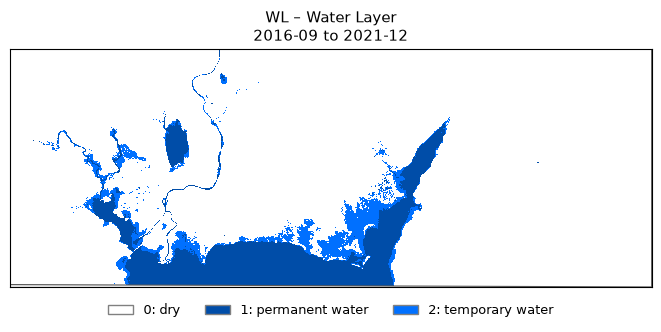

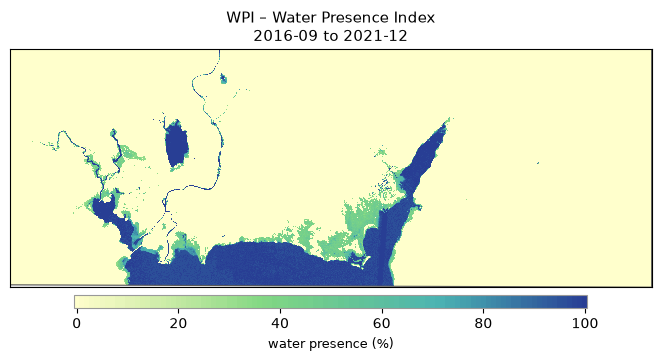

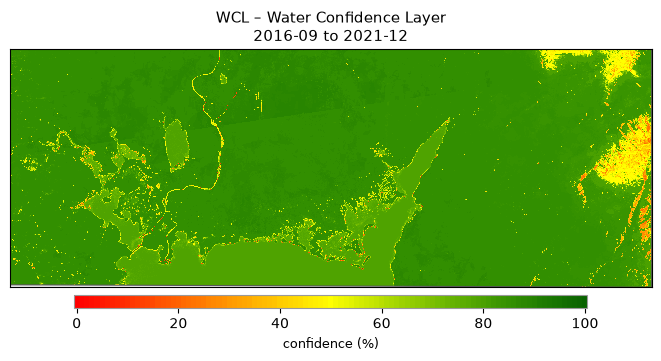

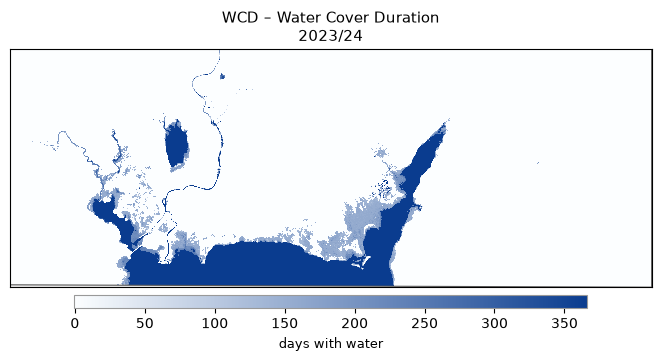

In [13]:
WCD_YEAR = 2023   # hydrological year of the WCD map by its start year (2020 = Sep 2020 – Aug 2021); None = latest
LAYER_FIG_WIDTH = 6.5   # width of each map (inches); adjust to screen size and resolution

# --- Load the layers --------------------------------------------------------
hrwl_period = max(layer_files("WL"))                    # latest HRWL package, if several were downloaded
wcd_files = layer_files("WCD")
wcd_by_year = {int(period[:4]): period for period in sorted(wcd_files)}
wcd_year = WCD_YEAR if WCD_YEAR is not None else max(wcd_by_year)
if wcd_year not in wcd_by_year:
    raise ValueError(f"WCD_YEAR = {wcd_year} not downloaded; available: {sorted(wcd_by_year)}")

maps = {}
for layer_name in ["WL", "WPI", "WCL", "WCD"]:
    period = hrwl_period if layer_name != "WCD" else wcd_by_year[wcd_year]
    paths = layer_files(layer_name)[period]
    data, aoi_transform = read_layer(paths, aoi_laea)
    maps[layer_name] = {"data": data, "legend": read_legend(paths[0]), "period": period_label(period), "tiles": len(paths)}

aoi_inside = ~np.ma.getmaskarray(maps["WL"]["data"])          # pixel centre within the AOI polygon
PIXEL_AREA_KM2 = abs(aoi_transform.a * aoi_transform.e) / 1e6

print(f"\nLayers loaded: {aoi_inside.shape[1]} x {aoi_inside.shape[0]} pixels of {PIXEL_AREA_KM2 * 1e6:.0f} m².")

extent = plotting_extent(maps["WL"]["data"], aoi_transform)
# One figure per layer; its height follows the AOI shape, plus room for title and legend
for layer_name, item in maps.items():
    fig, ax = map_axes(extent, aoi_laea, LAYER_FIG_WIDTH, extra_height=1.6)
    ax.imshow(legend_rgba(item["data"], item["legend"]), extent=extent, interpolation="nearest")
    ax.set_title(f"{layer_name} – {LAYERS[layer_name]['long_name']}\n{item['period']}", fontsize=11)
    add_layer_legend(ax, layer_name, item["data"], item["legend"])
    plt.show()

**Flags** are the same in all layers, only the value depends on the bit depth:

| Flag | HRWL layers (8-bit) | WCD (16-bit) |
|---|---|---|
| cloud or cloud shadow | 205 | 65485 |
| sea water | 253 | 65533 |
| no data | 255 | 65535 |

Flagged pixels are excluded from all statistics in Section 3. The table below is built from the colour tables shipped with the products. Runs of codes with the same meaning are merged into one row. The last column shows how much of the AOI each value range covers.

<h2>Section 3: Data analysis</h2>
<p>This section performs three distinct types of analyses on the water cover duration data (WCD) to extract meaningful insights and visualize the data.</p>

- <b>3a:</b> Water area computation and definition
- <b>3b:</b> Hotspot detection
- <b>3c:</b> Trend analysis of annual water duration

<h3>Section 3a: Water area computation and definition</h3>
The WCD time series is loaded for all hydrological years at once. From it we derive:

- <b>statistics</b> of the water cover duration in the AOI (mean, min, max and standard deviation) per year, as a table and a histogram;
- a <b>custom water mask</b> with your own thresholds for temporary and permanent water, compared to the HRWL WL and exported as GeoTIFF.

Results are written to the <code>results</code> folder.

<h4>3a) Step 1: Load the WCD time series</h4>
All years are stacked into one array (year × row × column) of days, with NaN for flagged pixels and pixels outside the AOI. It is reused in Sections 3b and 3c. Memory use is about 4 bytes × pixels × years (≈ 150 MB for a 370 km² AOI and 10 years).

In [14]:
wcd_years = sorted(wcd_by_year)
year_labels = [period_label(wcd_by_year[year]) for year in wcd_years]
wcd_stack = np.stack([as_values(read_layer(wcd_files[wcd_by_year[year]], aoi_laea)[0], "WCD") for year in wcd_years])

print(f"  [OK]      {len(wcd_years)} hydrological years: {year_labels[0]} to {year_labels[-1]}")
print(f"  └[INFO]   Stack of {wcd_stack.shape[0]} x {wcd_stack.shape[1]} x {wcd_stack.shape[2]} pixels, "
      f"{wcd_stack.nbytes / 1e6:,.0f} MB")

  [OK]      10 hydrological years: 2016/17 to 2025/26
  └[INFO]   Stack of 10 x 1891 x 5098 pixels, 386 MB


<h4>3a) Step 2: WCD statistics for the AOI</h4>
Per hydrological year, two views of the same data:

- **all AOI pixels**: includes dry land (WCD = 0), so the mean mostly reflects how much of the AOI is water;
- **water pixels (WCD > 0)**: only pixels that were water on at least one day, so the mean describes how long water stays.

`flagged (%)` is the share of AOI pixels without a valid value (cloud, sea, no data). The last row pools all years.

In [15]:
in_aoi = wcd_stack[:, aoi_inside]                       # years x AOI pixels
wcd_stats = pd.DataFrame([wcd_statistics(year_values, PIXEL_AREA_KM2) for year_values in in_aoi]
                         + [wcd_statistics(in_aoi, PIXEL_AREA_KM2)],
                         index=pd.Index(year_labels + ["all years"], name="hydrological year"))
wcd_stats.columns = pd.MultiIndex.from_tuples(wcd_stats.columns)
wcd_stats = wcd_stats.astype(float)

decimals = {"flagged (%)": 1, "mean": 2, "std": 2, "area (km²)": 2, "min": 0, "max": 0}
wcd_display = wcd_stats.round({column: decimals[column[1]] for column in wcd_stats.columns})

for column in wcd_display.columns:
    if column[1] in ("min", "max"):
        wcd_display[column] = wcd_display[column].astype("Int64")
display(wcd_display)
print("Values in days; 'area (km²)' of the pooled row is the average per year.")

all AOI pixels                   \
                  flagged (%)           mean min  max     std   
hydrological year                                               
2016/17                   0.0          37.51   0  366  106.26   
2017/18                   0.0          41.65   0  366  108.82   
2018/19                   0.0          38.65   0  366  107.40   
2019/20                   0.0          39.70   0  366  107.72   
2020/21                   0.0          42.21   0  366  110.11   
2021/22                   0.0          39.52   0  366  107.07   
2022/23                   0.0          42.11   0  366  108.75   
2023/24                   0.0          38.69   0  366  106.67   
2024/25                   0.0          38.18   0  366  106.77   
2025/26                   0.0          35.53   0  366  105.53   
all years                 0.0          39.38   0  366  107.54   

                  water pixels (WCD > 0)                           
                              area (km²)    mean min  max     std  
hydrological year                                                  
2016/17                           119.55  300.83  55  366  106.49  
2017/18                           136.46  292.64  55  366   98.77  
2018/19                           120.13  308.46  55  366   93.94  
2019/20                           125.92  302.25  55  366   94.87  
2020/21                           134.08  301.81  55  366   91.37  
2021/22                           127.37  297.51  55  366   97.68  
2022/23                           140.41  287.52  55  366  100.95  
2023/24                           122.24  303.47  55  366   94.26  
2024/25                           117.27  312.17  55  366   87.52  
2025/26                           101.87  334.41  55  366   69.68  
all years                         124.53  303.15  55  366   95.22

Values in days; 'area (km²)' of the pooled row is the average per year.


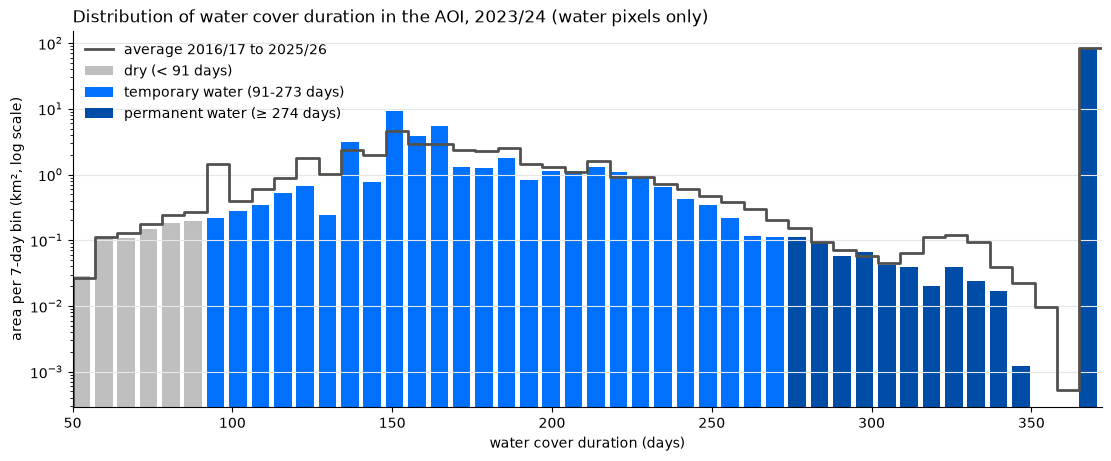

In [16]:
HIST_YEAR = wcd_year        # hydrological year (start year) for the histogram; default: the year shown in Section 2
BIN_DAYS = 7

hist_layer = in_aoi[wcd_years.index(HIST_YEAR)]
bins = np.arange(1, 367 + BIN_DAYS, BIN_DAYS)            # 1-10, 11-20, ... days; dry pixels (0) are left out
year_km2 = np.histogram(hist_layer[hist_layer > 0], bins)[0] * PIXEL_AREA_KM2
mean_km2 = np.histogram(in_aoi[in_aoi > 0], bins)[0] * PIXEL_AREA_KM2 / len(wcd_years)

# Bars in the WL colours of the class their days fall into; a bar spanning a threshold is split at it
wl_legend = maps["WL"]["legend"]
day_classes = [(1, HRWL_DAYS[0], "0.75", f"dry (< {HRWL_DAYS[0]} days)"),
               (HRWL_DAYS[0], HRWL_DAYS[1], wl_legend[2][0], f"temporary water ({HRWL_DAYS[0]}-{HRWL_DAYS[1] - 1} days)"),
               (HRWL_DAYS[1], bins[-1], wl_legend[1][0], f"permanent water (≥ {HRWL_DAYS[1]} days)")]
bar_left, bar_right = bins[:-1], bins[:-1] + BIN_DAYS - 1.5

fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
for lower, upper, colour, label in day_classes:
    left, right = np.clip(bar_left, lower, upper), np.clip(bar_right, lower, upper)
    ax.bar(left, year_km2, width=right - left, align="edge", color=colour, label=label)
ax.step(bins, np.append(mean_km2, mean_km2[-1]), where="post", color="#52514e", linewidth=2,
        label=f"average {year_labels[0]} to {year_labels[-1]}")
ax.set_yscale("log")
ax.set_xlim(50, bins[-1])
ax.set_xlabel("water cover duration (days)")
ax.set_ylabel(f"area per {BIN_DAYS}-day bin (km², log scale)")
ax.set_title(f"Distribution of water cover duration in the AOI, {period_label(wcd_by_year[HIST_YEAR])} "
             f"(water pixels only)", loc="left")
ax.grid(axis="y", color="0.9", which="major")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
plt.show()
min_wet = np.nanmin(np.where(in_aoi > 0, in_aoi, np.nan))

<h4>3a) Step 3: Define your own water mask</h4>
The HRWL WL uses a fixed definition of permanent and temporary water based on WCD thresholds: Temporary water refers to pixels with a water cover duration of >3 months (>25 % of the year, >91 days), and permanent water refers to pixels with a water coverage >9 months (>75 %, >274 days). 
<p>Map controls:</p>

- **WCD source**: Choice of reference period.
- **Water days**: Choice of thresholds; the lower handle is the minimum number of water days for <i>temporary water</i>, the upper handle the minimum for <i>permanent water</i>.
- **Reset** sets the slider to the thresholds of the HRWL definition.

The codes and colours are those of the WL, so the custom mask can be compared directly with the WL map in Section 2.

In [17]:
MASK_FIG_WIDTH = 10   # width of the mask map (inches); adjust to screen size and resolution

# Per-pixel mean over all years; years with flags are left out of the mean
n_observed = (~np.isnan(wcd_stack)).sum(axis=0)
wcd_mean = np.where(n_observed > 0, np.nansum(wcd_stack, axis=0) / np.maximum(n_observed, 1), np.nan).astype(np.float32)

mask_sources = {f"mean {year_labels[0]} to {year_labels[-1]}": wcd_mean}
mask_sources.update({f"year {label}": layer for label, layer in zip(year_labels, wcd_stack)})


def build_water_mask(wcd, temporary_from, permanent_from):
    """Classify WCD days with WL codes: 0 dry, 1 permanent water, 2 temporary water, 255 no data."""
    observed = ~np.isnan(wcd)
    days = np.where(observed, wcd, -1)
    mask = np.full(wcd.shape, MASK_NODATA, dtype=np.uint8)
    mask[observed] = 0
    mask[days >= temporary_from] = 2
    mask[days >= permanent_from] = 1
    return mask


def render_custom_mask(source, days):
    """Custom mask map as PNG bytes."""
    temporary_from, permanent_from = days
    mask = build_water_mask(mask_sources[source], temporary_from, permanent_from)
    # Height follows the AOI shape, plus room for the two-line title and the legend
    fig, ax = map_axes(extent, aoi_laea, MASK_FIG_WIDTH, extra_height=1.0)
    ax.imshow(legend_rgba(np.ma.MaskedArray(mask, ~aoi_inside), wl_legend), extent=extent, interpolation="nearest")
    ax.set_title(f"Custom mask ({source})\ntemporary ≥ {temporary_from} days, permanent ≥ {permanent_from} days",
                 fontsize=11)
    fig.legend(handles=legend_patches(wl_legend, MASK_CLASSES, with_code=False), loc="outside lower center",
               ncol=3)
    png = io.BytesIO()
    fig.savefig(png, format="png", dpi=250)
    plt.close(fig)   # never shown through the inline backend, only as the PNG below
    return png.getvalue()


source_picker = widgets.Dropdown(options=list(mask_sources), description="WCD source",
                                 style={"description_width": "initial"})
days_slider = widgets.IntRangeSlider(value=HRWL_DAYS, min=1, max=366, description="Water days",
                                     continuous_update=False, layout=widgets.Layout(width="520px"))
reset_button = widgets.Button(description="Reset", icon="undo",
                              tooltip=f"temporary ≥ {HRWL_DAYS[0]} days, permanent ≥ {HRWL_DAYS[1]} days",
                              layout=widgets.Layout(width="auto"))
reset_button.on_click(lambda button: setattr(days_slider, "value", HRWL_DAYS))   # the slider then redraws the mask
mask_image = widgets.Image(format="png")


def update_custom_mask(change=None):
    mask_image.value = render_custom_mask(source_picker.value, days_slider.value)


source_picker.observe(update_custom_mask, names="value")
days_slider.observe(update_custom_mask, names="value")
display(widgets.VBox([widgets.HBox([source_picker, days_slider, reset_button]), mask_image]))
update_custom_mask()

<h4>3a) Step 4: Export the custom water mask</h4>
Writes the mask with the current slider settings as a GeoTIFF (LAEA, 10 m, 8-bit, LZW-compressed) to <code>results</code>. The file carries the WL colour table and the thresholds as metadata, so it opens styled in QGIS or ArcGIS. The mask is also kept in memory as <code>custom_mask</code> for Section 3b; re-run this cell after changing the sliders.

In [18]:
mask_source = source_picker.value
temporary_from, permanent_from = days_slider.value
custom_mask = build_water_mask(mask_sources[mask_source], temporary_from, permanent_from)
custom_mask[~aoi_inside] = MASK_NODATA

source_tag = re.sub(r"[^0-9a-z]+", "-", mask_source.lower()).strip("-")
mask_path = write_geotiff(
    os.path.join(RESULTS_DIR, f"custom_water_mask_{source_tag}_T{temporary_from}_P{permanent_from}.tif"),
    custom_mask, aoi_transform, MASK_NODATA,
    colormap=palette(wl_legend, [*MASK_CLASSES, MASK_NODATA]),
    tags={"wcd_source": mask_source, "temporary_water_from_days": temporary_from,
          "permanent_water_from_days": permanent_from,
          "classes": "0 dry, 1 permanent water, 2 temporary water, 255 no data"})
print(f"  [OK]      Custom water mask written: {mask_path}")
print(f"  └[INFO]   {mask_source}, temporary ≥ {temporary_from} days, permanent ≥ {permanent_from} days")

  [OK]      Custom water mask written: results\custom_water_mask_mean-2016-17-to-2025-26_T91_P274.tif
  └[INFO]   mean 2016/17 to 2025/26, temporary ≥ 91 days, permanent ≥ 274 days


<h3>Section 3b: Hotspot detection</h3>
Which are the largest water bodies in the AOI, and in which year did their water area change most?

1. <b>Water bodies</b> are taken from <b>EU-Hydro</b> (see <i>Setup: Auxiliary files</i>): every polygon of the layers `InlandWater`, `River_Net_p`, `Canals_p`, `Ditches_p` and `Coastal_p` that lies in the AOI is one water body. <b>Fallback</b>: if the EU-Hydro file is missing or none of its water bodies lie in the AOI, the water bodies are derived from the custom mask of Section 3a instead: all connected water pixels (permanent + temporary) form one water body; diagonal neighbours count as connected. The bodies are ranked by area.
2. For the largest bodies, the <b>water area</b> is computed for every hydrological year: pixels within the body's <b>counting zone</b> with at least as many water days as the <i>temporary water</i> threshold of the mask. The counting zone is the body's outline plus a ring of <code>BODY_BUFFER_M</code> metres around it, so that water spreading beyond the outline is counted as a gain.
3. The year-to-year step with the largest absolute change in water area is the <b>hotspot year of that body</b>.

Water bodies are clipped at the AOI boundary, so a lake that extends beyond the AOI is only counted in part. Reference outlines (EU-Hydro) show a body at one point in time: a lake that shrinks shows its loss within the outline, but a lake that floods its shores would show no gain if only the outline were counted. The buffer ring captures such gains up to <code>BODY_BUFFER_M</code> beyond the outline. Pixels of other water bodies in the ring are left out, so a ring does not take over an adjacent river or pond; where the rings of two bodies overlap, the larger body keeps the pixel.

<p><b>Results</b> are exported as a map (PNG), a table (CSV) and polygons with all attributes (GeoPackage).</p>

<h4>3b) Step 1: Identify largest bodies of water based on EU Hydro</h4>
Set <code>N_BODIES</code> for the number of bodies to analyse and <code>MIN_BODY_AREA_KM2</code> to ignore very small ones. <code>BODY_BUFFER_M</code> sets how far beyond its outline the water of a body is counted (0 = outline only). A wider ring catches larger floods, but also more unrelated wet areas such as nearby wetlands or flooded fields. The column <code>source</code> tells where each body comes from (EU-Hydro layer or WCD custom mask); <code>name</code> and <code>euhydro_id</code> are the EU-Hydro name (where known) and object ID.


In [19]:
N_BODIES = 10                 # number of largest water bodies to analyse
MIN_BODY_AREA_KM2 = 0.01       # ignore bodies smaller than this (0.01 km² = 1 ha = 100 pixels)
BODY_BUFFER_M = 100            # water up to this distance beyond the outline still counts (100 m = 10 pixels)


def euhydro_water_bodies(path, layers, aoi):
    """EU-Hydro polygons of the given layers within the AOI, clipped to it: one row per EU-Hydro feature."""
    found = []
    available = fiona.listlayers(path)
    for layer in [layer for layer in layers if layer in available]:
        # The mask makes GDAL read only the features near the AOI instead of the whole river basin.
        # EU-Hydro stores measured (M) geometries and some non-standard dates; the reader handles both
        # but warns about every layer, so these harmless warnings are silenced here.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="Measured \\(M\\) geometry types are not supported")
            warnings.filterwarnings("ignore", message="Non-conformant content for record")
            features = gpd.read_file(path, layer=layer, mask=aoi)
        if features.empty:
            continue
        features = gpd.clip(features.to_crs(LAEA_CRS), aoi, keep_geom_type=True)
        features = features[~features.is_empty]
        # Only InlandWater carries names; 'UNK' marks an unnamed lake
        names = features["NAM"].fillna("").astype(str) if "NAM" in features else pd.Series("", index=features.index)
        found.append(gpd.GeoDataFrame({
            "source": f"EU-Hydro {layer}",
            "name": names.where(names != "UNK", ""),
            "euhydro_id": features["OBJECT_ID"].astype(str),
        }, geometry=[force_2d(geom) for geom in features.geometry], crs=LAEA_CRS))   # drop the z values
    if not found:
        return gpd.GeoDataFrame({"source": [], "name": [], "euhydro_id": []}, geometry=[], crs=LAEA_CRS)
    return pd.concat(found, ignore_index=True)


# --- Primary: EU-Hydro reference water bodies -----------------------------------
water_bodies = None
if euhydro_layers:
    water_bodies = euhydro_water_bodies(EUHYDRO_PATH, euhydro_layers, aoi_laea)
    if water_bodies.empty:
        print(f"  [INFO]    No EU-Hydro water bodies in the AOI ({', '.join(euhydro_layers)}).")
        water_bodies = None
    else:
        print(f"  [OK]      Water bodies from EU-Hydro: {os.path.basename(EUHYDRO_PATH)}")
        for source, count in water_bodies["source"].value_counts().items():
            print(f"  └[INFO]   {source:<22} {count:>5,} polygons")

# --- Fallback: connected water pixels of the custom mask --------------------------
if water_bodies is None:
    print("  [INFO]    Fallback: water bodies derived from the custom mask of Section 3a.")
    # Each connected region of water pixels becomes one polygon (8-connectivity: diagonal neighbours belong together)
    is_water = np.isin(custom_mask, [1, 2])
    water_bodies = gpd.GeoDataFrame(
        geometry=[shape(geom) for geom, _ in shapes(is_water.astype(np.uint8), mask=is_water,
                                                    connectivity=8, transform=aoi_transform)],
        crs=LAEA_CRS)
    water_bodies.insert(0, "source", "WCD custom mask")
body_source = "EU-Hydro" if water_bodies["source"].iloc[0].startswith("EU-Hydro") else "WCD custom mask"
water_bodies["area_km2"] = water_bodies.area / 1e6

largest = (water_bodies[water_bodies["area_km2"] >= MIN_BODY_AREA_KM2]
           .nlargest(N_BODIES, "area_km2").reset_index(drop=True))
largest.insert(0, "rank", np.arange(1, len(largest) + 1))
if largest.empty:
    raise RuntimeError("No water body reaches MIN_BODY_AREA_KM2; lower it (or, for the fallback, "
                       "the mask thresholds in Section 3a).")

print(f"  [OK]      {len(water_bodies):,} water bodies ({body_source}), {water_bodies['area_km2'].sum():,.2f} km² in total")
print(f"  └[INFO]   The {len(largest)} largest cover {largest['area_km2'].sum():,.2f} km² "
      f"({largest['area_km2'].sum() / water_bodies['area_km2'].sum():.0%} of the water area)")
display(largest.drop(columns="geometry").set_index("rank").round({"area_km2": 3}))


  [OK]      Water bodies from EU-Hydro: euhydro_danube_v013.gpkg
  └[INFO]   EU-Hydro InlandWater      20 polygons
  └[INFO]   EU-Hydro River_Net_p       3 polygons
  [OK]      23 water bodies (EU-Hydro), 102.66 km² in total
  └[INFO]   The 10 largest cover 102.13 km² (99% of the water area)


,source,name,euhydro_id,area_km2
rank,,,,
1,EU-Hydro InlandWater,,IW35000128,83.149
2,EU-Hydro InlandWater,,IW35017166,7.005
3,EU-Hydro InlandWater,,IW35001920,5.802
4,EU-Hydro River_Net_p,,RP35000080,2.857
5,EU-Hydro River_Net_p,,RP35000075,1.898
6,EU-Hydro InlandWater,,IW35001927,0.461
7,EU-Hydro InlandWater,,IW35002226,0.419
8,EU-Hydro River_Net_p,,RP35000077,0.203
9,EU-Hydro InlandWater,,IW35000088,0.178


<h4>3b) Step 2: Year of largest change per water body</h4>
The counting zones (outline + buffer ring) are burnt back onto the 10 m grid, so every pixel knows its water body. The yearly water area of all bodies is then summed in one pass per year (<code>np.bincount</code>), without looping over bodies. The table lists the average, minimum and maximum water area of each body and its largest change between two consecutive years. The rows are ordered by <code>rank</code>, the size rank from Step 1, which also labels the bodies on the map. The map colours each body by the size and direction of that change in percent of the body's mean area (red: loss, blue: gain), the same colour scale as the bar charts in Step 3, so bodies of different size can be compared. The same value is listed as <code>change_pct</code> in the table: the change in percent of the body's mean area over all years, so a loss and a gain of the same size get the same percentage.

,mean_area_km2,min_area_km2,max_area_km2,change_km2,change_pct
rank,,,,,
1,85.605,81.316,87.032,-3.829,-4.5
2,7.405,6.764,7.632,-0.412,-5.6
3,5.530,5.134,5.801,-0.461,-8.3
4,2.117,1.888,2.341,-0.334,-15.8
5,2.635,1.536,3.353,-0.991,-37.6
6,0.222,0.117,0.369,-0.130,-58.6
7,0.348,0.163,0.531,0.218,62.7
8,0.171,0.136,0.267,-0.113,-66.0
9,0.364,0.150,0.398,-0.226,-62.2


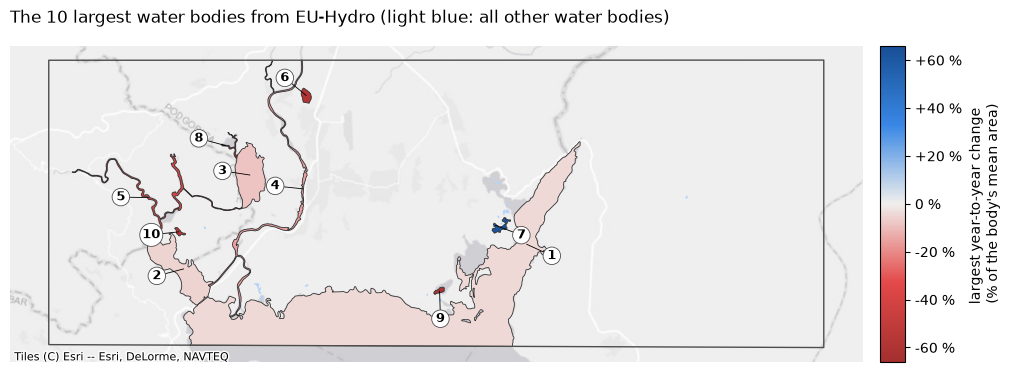

In [20]:
# Counting zone of each body: its outline plus a ring of BODY_BUFFER_M, so that flooding beyond the outline
# counts as a gain. Burn order (later shapes overwrite earlier ones):
#   1. outline + ring, smallest body first: where two rings overlap, the larger body keeps the pixel
#   2. all water bodies with 0: a ring does not take over an adjacent river or pond
#   3. outlines, smallest body first: every body keeps its own outline
zones = largest.geometry.buffer(BODY_BUFFER_M).intersection(aoi_laea.geometry.iloc[0])
smallest_first = largest.index[::-1]
burn = [*zip(zones[smallest_first], largest.loc[smallest_first, "rank"]),
        *((geom, 0) for geom in water_bodies.geometry),
        *zip(largest.geometry[smallest_first], largest.loc[smallest_first, "rank"])]
body_id = rasterize(burn, out_shape=custom_mask.shape, transform=aoi_transform, fill=0, dtype="int32")
in_body = body_id > 0
ids = body_id[in_body]
n_bodies = len(largest)
body_pixels = np.bincount(ids, minlength=n_bodies + 1)[1:]
if (body_pixels == 0).any():   # outlines narrower than a pixel, or hidden below an overlapping body
    print(f"  [WARNING] No pixel centre within body {', '.join(map(str, np.flatnonzero(body_pixels == 0) + 1))}; "
          "its water area stays 0")

# years x bodies: water area (km²)
yearly_area = np.empty((len(wcd_years), n_bodies))
for i, year_wcd in enumerate(wcd_stack):
    days = year_wcd[in_body]
    is_wet = np.nan_to_num(days, nan=-1) >= temporary_from
    yearly_area[i] = np.bincount(ids, weights=is_wet, minlength=n_bodies + 1)[1:] * PIXEL_AREA_KM2

# Largest absolute change between two consecutive years
steps = np.diff(yearly_area, axis=0)                        # (years - 1) x bodies
hotspot = np.abs(steps).argmax(axis=0)
body_idx = np.arange(n_bodies)

largest["mean_area_km2"] = yearly_area.mean(axis=0)
largest["min_area_km2"] = yearly_area.min(axis=0)
largest["max_area_km2"] = yearly_area.max(axis=0)
largest["largest_change"] = [f"{year_labels[i]} → {year_labels[i + 1]}" for i in hotspot]
largest["change_km2"] = steps[hotspot, body_idx]
# in percent of the mean area: the same scale for losses and gains, and the same as the bar charts in Step 3
largest["change_pct"] = 100 * largest["change_km2"] / largest["mean_area_km2"].where(largest["mean_area_km2"] > 0)

area_by_year = pd.DataFrame(yearly_area.T, index=pd.Index(largest["rank"], name="rank"), columns=year_labels)

# These columns are kept for the export in Step 3, but not shown here (name and euhydro_id exist for EU-Hydro only)
hotspot_table = largest.drop(columns=["geometry", "source", "name", "euhydro_id", "area_km2", "largest_change"],
                             errors="ignore").set_index("rank")
display(hotspot_table.round({"mean_area_km2": 3, "min_area_km2": 3, "max_area_km2": 3,
                             "change_km2": 3, "change_pct": 1}))

# --- Map ------------------------------------------------------------------------
# Colour: change_pct, the largest change in percent of the body's mean area (same scale as the bar charts in Step 3)
limit = max(np.nanmax(np.abs(largest["change_pct"]), initial=0), 1)
fig, ax = plt.subplots(figsize=(10, 10), layout="constrained")
aoi_laea.boundary.plot(ax=ax, color="0.3", linewidth=1)
water_bodies.plot(ax=ax, color="#b7d3f6", linewidth=0)
cax = ax.inset_axes([1.02, 0, 0.03, 1])   # colour bar as tall as the map
largest.plot(
    ax=ax, column="change_pct", cmap=LOSS_GAIN_CMAP, norm=TwoSlopeNorm(0, -limit, limit),
    edgecolor="0.2", linewidth=0.6, legend=True, cax=cax, missing_kwds={"color": "white"},
    legend_kwds={"label": "largest year-to-year change \n(% of the body's mean area)",
                 "format": signed_percent})
# Rank labels are offset outwards from the AOI centre, with a leader line to a point inside their body
LABEL_OFFSET_PT = 20          # distance between label and body (points)
centre = aoi_laea.geometry.iloc[0].centroid
for _, body in largest.iterrows():
    point = body.geometry.representative_point()
    direction = np.array([point.x - centre.x, point.y - centre.y])
    norm = np.hypot(*direction)
    direction = direction / norm if norm > 0 else np.array([0.0, 1.0])   # body at the centre -> label above
    ax.annotate(str(body["rank"]), (point.x, point.y), xytext=LABEL_OFFSET_PT * direction,
                textcoords="offset points", ha="center", va="center", fontsize=9, fontweight="bold",
                bbox={"boxstyle": "circle,pad=0.2", "facecolor": "white", "edgecolor": "0.3", "linewidth": 0.6},
                arrowprops={"arrowstyle": "-", "color": "black", "linewidth": 0.6, "shrinkA": 0, "shrinkB": 0})
add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, zorder=0)
ax.set_title(f"The {n_bodies} largest water bodies from {body_source} (light blue: all other water bodies)", loc="left")
ax.set_axis_off()
map_path = os.path.join(RESULTS_DIR, "water_bodies_map.png")
fig.savefig(map_path, dpi=150)
plt.show()

<h4>3b) Step 3: Water area per year and export</h4>
The table lists the water area of every body per hydrological year. One small chart per water body shows the same time series. Each bar is coloured by the change from the previous year in percent of the body's mean area, i.e. by the height difference to the bar before it (red: loss, blue: gain; the first year has no previous value and stays white). A line on top of the bars connects the two years of the largest change. The y axis shows the deviation of the water area from the body's mean area in percent (0 % = mean area), so bars above the zero line are wetter and bars below it drier than average. All charts share the same symmetric y range, set by the largest deviation of all bodies, so changes can be compared between bodies of different size. Finally, the water bodies with all values are exported as GeoPackage and CSV.

Water area per hydrological year (km²):


,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26
rank,,,,,,,,,,
1,85.593,87.032,85.654,86.338,86.469,85.675,86.822,86.007,85.145,81.316
2,7.330,7.518,7.415,7.566,7.625,7.559,7.632,7.464,7.176,6.764
3,5.474,5.594,5.498,5.564,5.757,5.598,5.801,5.671,5.210,5.134
4,2.008,2.341,2.159,2.134,2.311,1.977,2.276,2.065,2.009,1.888
5,2.244,2.588,3.112,3.206,3.353,3.113,3.256,2.265,1.676,1.536
6,0.338,0.369,0.366,0.294,0.164,0.117,0.146,0.146,0.147,0.137
7,0.313,0.531,0.356,0.383,0.403,0.358,0.363,0.365,0.242,0.163
8,0.173,0.267,0.154,0.165,0.179,0.147,0.186,0.150,0.152,0.136
9,0.390,0.398,0.380,0.397,0.389,0.382,0.394,0.386,0.376,0.150


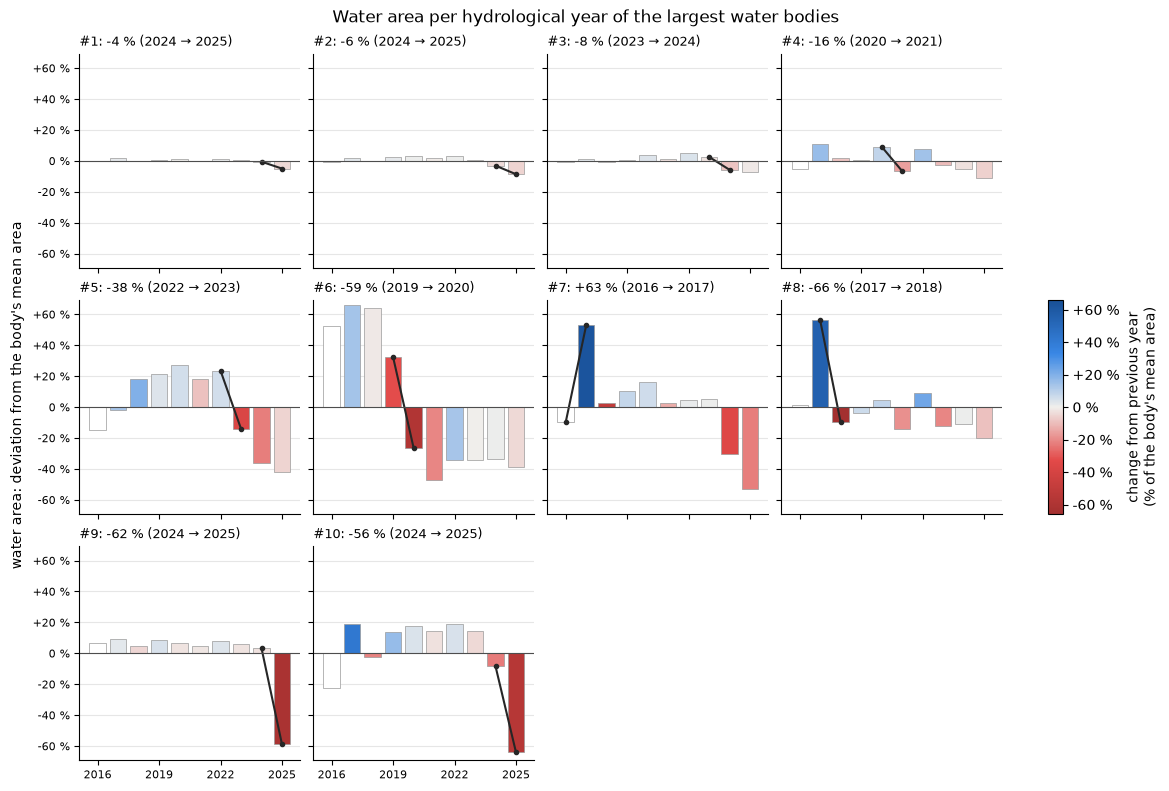

  [OK]      Written: results\water_bodies_map.png
  [OK]      Written: results\water_bodies.csv
  [OK]      Written: results\water_bodies.gpkg


In [21]:
print("Water area per hydrological year (km²):")
display(area_by_year.round(3))

# --- Small multiples: water area per year --------------------------------------
n_cols = min(4, n_bodies)
n_rows = int(np.ceil(n_bodies / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.9 * n_cols, 2.6 * n_rows), sharex=True, sharey=True,
                         layout="constrained", squeeze=False)
year_pos = np.arange(len(wcd_years))
# Relative water area: deviation from the mean area of the body (0 % = mean); one symmetric y range for all bodies
body_mean = area_by_year.mean(axis=1)
relative_area = 100 * area_by_year.div(body_mean.where(body_mean > 0), axis=0) - 100
rel_limit = 1.05 * max(np.nanmax(np.abs(relative_area.to_numpy()), initial=0), 1)
# Colour: change from the previous year in percent of the body's mean area (= height difference of two bars)
relative_steps = np.diff(relative_area.to_numpy(), axis=1)   # bodies x (years - 1)
step_limit = max(np.nanmax(np.abs(relative_steps), initial=0), 1)
change_norm = TwoSlopeNorm(0, -step_limit, step_limit)
for ax, (_, body), column, step in zip(axes.flat, largest.iterrows(), relative_steps, hotspot):
    area = relative_area.loc[body["rank"]].to_numpy()
    colours = np.vstack([[1, 1, 1, 1], LOSS_GAIN_CMAP(change_norm(column))])   # first year: no previous value
    ax.bar(year_pos, area, color=colours, edgecolor="0.6", linewidth=0.5, width=0.8)
    ax.plot([step, step + 1], area[[step, step + 1]], color="0.15", linewidth=1.5, marker="o", markersize=3)
    ax.axhline(0, color="0.3", linewidth=0.8)
    ax.set_title(f"#{body['rank']}: {area[step + 1] - area[step]:+.0f} % ({year_labels[step][:4]} → {year_labels[step + 1][:4]})",
                 fontsize=9, loc="left")
    ax.set_xticks(year_pos[::3], [label[:4] for label in year_labels[::3]], fontsize=8)
    ax.yaxis.set_major_formatter(signed_percent)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[n_bodies:]:
    ax.set_visible(False)
axes[0, 0].set_ylim(-rel_limit, rel_limit)
# One colour bar for all charts, vertically centred and as tall as one chart: lay out once to measure the charts
colorbar_kwargs = {"mappable": ScalarMappable(change_norm, LOSS_GAIN_CMAP), "ax": axes, "aspect": 15,
                   "label": "change from previous year\n(% of the body's mean area)",
                   "format": signed_percent}
colorbar = fig.colorbar(**colorbar_kwargs)
fig.draw_without_rendering()
top, bottom = axes[0, 0].get_position(), axes[-1, 0].get_position()
colorbar.remove()
fig.colorbar(shrink=top.height / (top.y1 - bottom.y0), **colorbar_kwargs)
fig.supylabel("water area: deviation from the body's mean area", fontsize=10)
fig.suptitle("Water area per hydrological year of the largest water bodies", fontsize=12)
plt.show()

# --- Export -----------------------------------------------------------------------
export = largest.copy()
for label, column in zip(year_labels, yearly_area):
    export[f"area_{label.replace('/', '_')}_km2"] = column
export["body_source"] = body_source
export["buffer_m"] = BODY_BUFFER_M
export["mask_source"] = mask_source
export["temporary_from_days"] = temporary_from
gpkg_path = os.path.join(RESULTS_DIR, "water_bodies.gpkg")
csv_path = os.path.join(RESULTS_DIR, "water_bodies.csv")
export.to_file(gpkg_path, layer="largest_water_bodies", driver="GPKG")
export.drop(columns="geometry").to_csv(csv_path, index=False)
for path in (map_path, csv_path, gpkg_path):
    print(f"  [OK]      Written: {path}")

<h3>Section 3c: Trend in annual water duration</h3>
Analysis of the trend in annual water cover duration over the entire reference period.

<h4>3c) Step 1: Average water cover duration per year across entire AOI</h4>
The average WCD per hydrological year is shown as a bar chart, with a linear fit through the yearly averages.

<code>TREND_DOMAIN</code> selects the pixels that are averaged:

- `"water"` (default): pixels that were water on at least one day in at least one year. Dry land, which would only dilute the average, is left out, and the pixel set is the same for every year, so the bars can be compared.
- `"aoi"`: all AOI pixels.

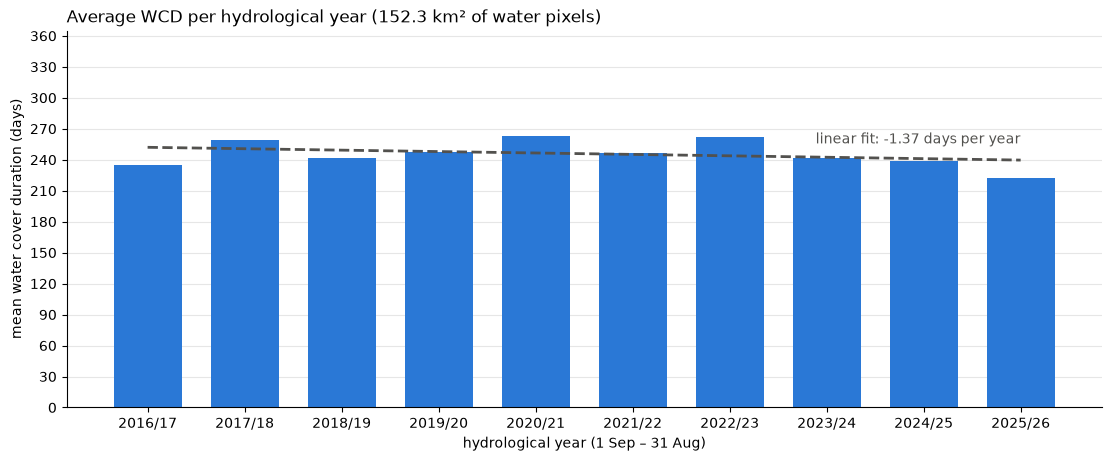

hydrological year,2016/17,2017/18,2018/19,2019/20,2020/21,2021/22,2022/23,2023/24,2024/25,2025/26
mean WCD (days),234.7,259.6,241.5,247.7,262.9,246.7,262.3,241.8,238.6,222.6
valid pixels (%),100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [22]:
TREND_DOMAIN = "water"        # "water" or "aoi"

# Compute annual mean water cover duration for the selected domain
ever_wet = aoi_inside & (np.nan_to_num(wcd_stack, nan=0) > 0).any(axis=0)
domain = ever_wet if TREND_DOMAIN == "water" else aoi_inside
domain_values = wcd_stack[:, domain]
n_valid = (~np.isnan(domain_values)).sum(axis=1)
annual_mean = np.nansum(domain_values, axis=1) / np.maximum(n_valid, 1)
annual_mean[n_valid == 0] = np.nan

fit = np.polyfit(np.array(wcd_years)[n_valid > 0], annual_mean[n_valid > 0], 1)

# Figure: Annual mean water cover duration with linear trend fit
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
year_pos = np.arange(len(wcd_years))
ax.bar(year_pos, annual_mean, color="#2a78d6", width=0.7)
ax.plot(year_pos, np.polyval(fit, wcd_years), color="#52514e", linewidth=2, linestyle="--")
ax.annotate(f"linear fit: {fit[0]:+.2f} days per year", (year_pos[-1], np.polyval(fit, wcd_years[-1])),
            xytext=(0, 12), textcoords="offset points", ha="right", color="#52514e")
ax.set_xticks(year_pos, year_labels)
ax.set_xlabel("hydrological year (1 Sep – 31 Aug)")
ax.set_ylabel("mean water cover duration (days)")
ax.set_ylim(0, 365)
ax.set_yticks(np.arange(0, 365, 30))
domain_text = f"{domain.sum() * PIXEL_AREA_KM2:,.1f} km² of " + ("water pixels" if TREND_DOMAIN == "water" else "AOI")
ax.set_title(f"Average WCD per hydrological year ({domain_text})", loc="left")
ax.grid(axis="y", color="0.9")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

display(pd.DataFrame({"mean WCD (days)": annual_mean, "valid pixels (%)": 100 * n_valid / domain.sum()},
                     index=pd.Index(year_labels, name="hydrological year")).round(1).T)

<h4>3c) Step 2: Per-pixel trend</h4>
Step 1 reduced the whole water area to one number per year. Step 2 repeats the trend analysis for every single pixel and shows <b>where</b> water duration changes.

For every pixel, an ordinary least-squares line is fitted through its WCD values over the years:

$$\text{slope} = \frac{n\sum xy - \sum x \sum y}{n\sum x^2 - \left(\sum x\right)^2}$$

with $x$ the year, $y$ the WCD and $n$ the number of valid years of that pixel. Years without valid data are left out per pixel.

**Slope** is the average change of the pixel's water cover duration from one year to the next, in days per year, according to OLS linear regression per pixel.


Each pixel is assigned to one of the following classes:

| Class | Rule | Code |
|---|---|---|
| no water | never water in any year | 0 |
| decreasing | slope < −`STABLE_SLOPE` | 1 |
| stable | \|slope\| ≤ `STABLE_SLOPE` | 2 |
| increasing | slope > `STABLE_SLOPE` | 3 |
| no data | fewer than `MIN_YEARS` valid years, or outside the AOI | 255 |

`STABLE_SLOPE` is in days per year; the default of 3 days per year means that a change of about a month over the decade still counts as stable.

In [23]:
STABLE_SLOPE = 3.0      # days per year; smaller absolute slopes count as stable
MIN_YEARS = 5           # minimum number of valid years for a trend
TREND_NODATA = 255
TREND_LEGEND = {         # code: (RGBA, label), same structure as the product legends
    0: ((1.0, 1.0, 1.0, 1.0), "no water"),
    1: ((0xe3 / 255, 0x49 / 255, 0x48 / 255, 1.0), "decreasing"),
    2: ((0xbd / 255, 0xbc / 255, 0xb6 / 255, 1.0), "stable"),
    3: ((0x2a / 255, 0x78 / 255, 0xd6 / 255, 1.0), "increasing"),
    TREND_NODATA: ((0.0, 0.0, 0.0, 0.0), "no data"),
}

start = time.perf_counter()
years_centred = np.array(wcd_years, dtype=np.float32) - np.mean(wcd_years)
valid = ~np.isnan(wcd_stack)
y = np.where(valid, wcd_stack, 0).astype(np.float32)
x = valid * years_centred[:, None, None]                # year where valid, 0 otherwise

n = valid.sum(axis=0)
sum_x, sum_y = x.sum(axis=0), y.sum(axis=0)
sum_xx, sum_xy = (x * x).sum(axis=0), (x * y).sum(axis=0)
denominator = n * sum_xx - sum_x ** 2
with np.errstate(divide="ignore", invalid="ignore"):
    slope = ((n * sum_xy - sum_x * sum_y) / denominator).astype(np.float32)
slope[(n < MIN_YEARS) | (denominator == 0) | ~aoi_inside] = np.nan
del x, y                                                # free the temporary stacks

has_trend = ~np.isnan(slope)
trend_class = np.full(slope.shape, TREND_NODATA, dtype=np.uint8)
trend_class[has_trend & ~ever_wet] = 0
trend_class[has_trend & ever_wet & (slope < -STABLE_SLOPE)] = 1
trend_class[has_trend & ever_wet & (np.abs(slope) <= STABLE_SLOPE)] = 2
trend_class[has_trend & ever_wet & (slope > STABLE_SLOPE)] = 3
elapsed = time.perf_counter() - start

print(f"  [OK]      Trend computed for {has_trend.sum():,} pixels in {elapsed:.1f} s")
trend_summary = pd.DataFrame({
    "area (km²)": [(trend_class == code).sum() * PIXEL_AREA_KM2 for code in TREND_LEGEND],
    "share of water pixels (%)": [100 * (trend_class == code).sum() / max(ever_wet.sum(), 1) if code in (1, 2, 3)
                                  else np.nan for code in TREND_LEGEND],
}, index=pd.Index([label for _, label in TREND_LEGEND.values()], name="trend class"))
display(trend_summary.round(2))

  [OK]      Trend computed for 9,587,540 pixels in 2.3 s


,area (km²),share of water pixels (%)
trend class,,
no water,806.47,NaN
decreasing,38.99,25.60
stable,102.08,67.03
increasing,11.22,7.37
no data,5.28,NaN


Two <b>trend maps</b> visualize the analysis.
1. Continuous map of the slope of each pixel
2. Categorical map (decreasing/stable/increasing) derived from the continuous data

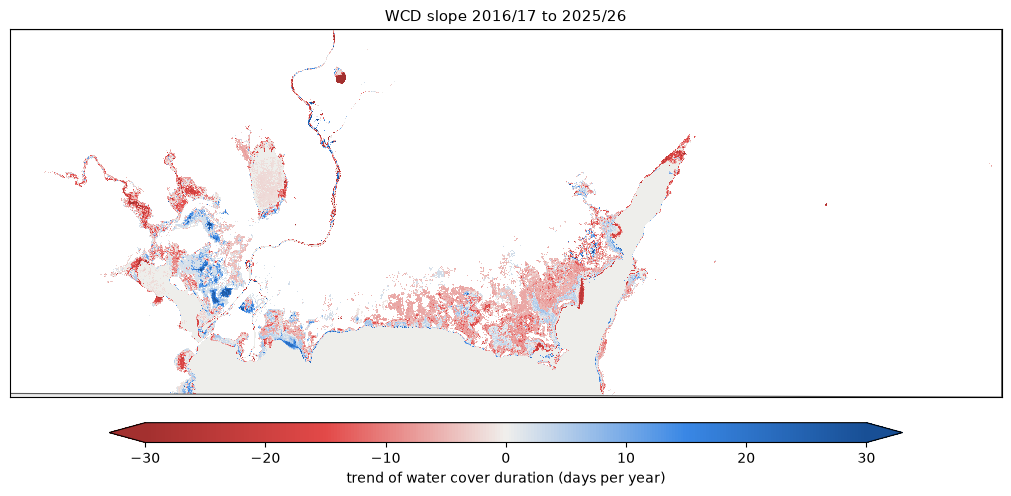

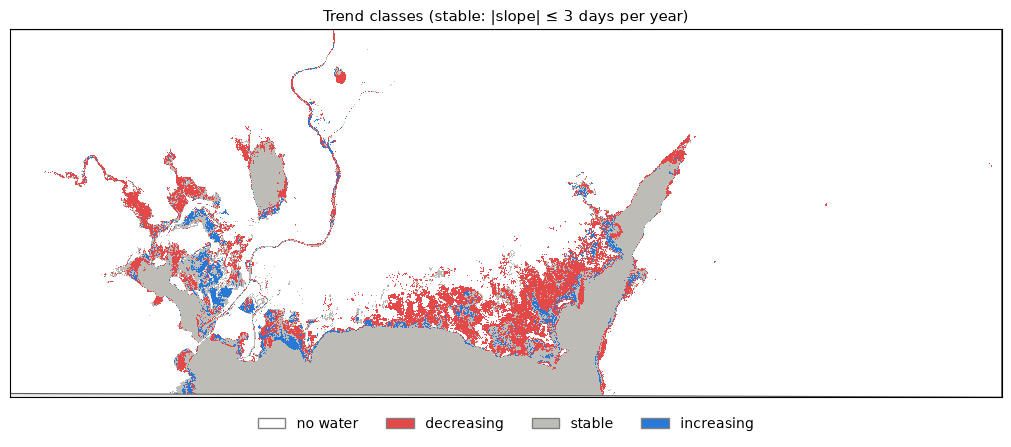

  [OK]      Written: results\wcd_trend_slope.tif
  [OK]      Written: results\wcd_trend_class.tif


In [24]:
SLOPE_LIMIT = 30        # colour scale of the slope map: ± days per year
TREND_FIG_WIDTH = 10    # width of the trend maps (inches); adjust to screen size and resolution

slope_map = np.ma.MaskedArray(slope, mask=~(has_trend & ever_wet))
land = np.ma.MaskedArray(np.zeros(slope.shape), mask=~aoi_inside)     # white underlay for 'no water' pixels


# --- Slope map ------------------------------------------------------------------
fig, ax = map_axes(extent, aoi_laea, TREND_FIG_WIDTH, extra_height=1.6)
ax.imshow(land, extent=extent, cmap=ListedColormap(["white"]), interpolation="nearest")
image = ax.imshow(slope_map, extent=extent, cmap=LOSS_GAIN_CMAP, vmin=-SLOPE_LIMIT, vmax=SLOPE_LIMIT,
                  interpolation="nearest")
fig.colorbar(image, ax=ax, location="bottom", shrink=0.8, aspect=40, extend="both",
             label="trend of water cover duration (days per year)")
ax.set_title(f"WCD slope {year_labels[0]} to {year_labels[-1]}", fontsize=11)
plt.show()

# --- Class map ------------------------------------------------------------------
fig, ax = map_axes(extent, aoi_laea, TREND_FIG_WIDTH, extra_height=1.6)
ax.imshow(legend_rgba(np.ma.MaskedArray(trend_class, ~aoi_inside), TREND_LEGEND), extent=extent,
          interpolation="nearest")
ax.legend(handles=legend_patches(TREND_LEGEND, [0, 1, 2, 3], with_code=False), loc="upper center",
          bbox_to_anchor=(0.5, -0.02), ncol=4, frameon=False)
ax.set_title(f"Trend classes (stable: |slope| ≤ {STABLE_SLOPE:g} days per year)", fontsize=11)
plt.show()

tags = {"years": f"{year_labels[0]} to {year_labels[-1]}", "min_years": MIN_YEARS,
        "stable_slope_days_per_year": STABLE_SLOPE}
slope_path = write_geotiff(os.path.join(RESULTS_DIR, "wcd_trend_slope.tif"), slope, aoi_transform, np.nan,
                           tags={**tags, "unit": "days per year"})
class_path = write_geotiff(os.path.join(RESULTS_DIR, "wcd_trend_class.tif"), trend_class, aoi_transform, TREND_NODATA,
                           colormap=palette(TREND_LEGEND, TREND_LEGEND),
                           tags={**tags, "classes": "0 no water, 1 decreasing, 2 stable, 3 increasing, 255 no data"})
for path in (slope_path, class_path):
    print(f"  [OK]      Written: {path}")